# The UniVII experiment toolkit: public-data walkthrough

Learn reference geometry, inspect a **real RNA–protein mosaic atlas**, and normalize **real H&E images**. All default inputs download automatically; no private files, local inventory reports, or personal paths are required.

| Example | Public input | What it teaches |
|---|---|---|
| Healthy reference → AML projection | [van Galen et al., GSE116256](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE116256) | Learned curvature, prototypes, anchoring, tree comparison, descriptive pseudotime |
| Mosaic atlas | [10x PBMC 5k RNA + surface protein](https://docs.scvi-tools.org/en/stable/tutorials/notebooks/quick_start/data_loading.html) | Paired bridge with deliberately hidden modalities; joint embedding and marker overlays |
| Annotated transfer and adaptation | [SLN111 CITE-seq](https://docs.scvi-tools.org/en/stable/api/reference/scvi.data.spleen_lymph_cite_seq.html) | Bridge label transfer, confidence/novelty, and frozen-atlas new-batch adaptation |
| Histology | [TIAToolbox public H&E samples](https://tia-toolbox.readthedocs.io/en/stable/_notebooks/jnb/02-stain-normalization.html) | Macenko stain normalization, tissue QC, before/after inspection |

**These datasets are independent.** The H&E images are not paired with the AML or PBMC transcriptomes. PBMC mosaic groups are constructed from one real paired assay, not independent donor cohorts. This is a teaching notebook, not a clinical classifier or a benchmark establishing superiority of a geometry.

The default uses 10 training epochs to keep the walkthrough approachable. Increase epochs and use donor-held-out replication for scientific comparisons. The initial download includes the approximately 70 MB GEO archive plus the PBMC matrix and a few images. Allow several GB of RAM. Downloaded data and generated results stay in relative directories; do not commit these directories to GitHub.


This single notebook also demonstrates **annotated bridge label transfer**, **new-batch adaptation with a separate evaluation split**, and **nine matched geometry runs**. Every helper is defined inline. Data/results directories are generated automatically; no companion Python modules or notebooks are needed.

**Included execution:** all enabled sections ran with UniVII 0.2.0, 10 epochs per model, three geometry seeds and 10 adaptation epochs. All 11 figures are embedded for GitHub viewing. These are short demonstration runs, not converged benchmark claims.


In [1]:
# Python >=3.10. Run once in a fresh environment, then restart the kernel if needed.
# %pip install "univii[tutorials]==0.2.0" pillow


In [2]:
import os
os.environ['TQDM_DISABLE']='1'
from pathlib import Path
from datetime import datetime
DATA_MODE = 'public'  # or 'prepared' for an existing compatible AML preparation
PREPARED_DIR = Path('data/anchored_inputs')  # used only in prepared mode
CACHE = Path('data/toolkit_public')
DATA_DIR = CACHE/'prepared_aml' if DATA_MODE == 'public' else PREPARED_DIR
RESULTS = Path('results') / ('toolkit_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
N_EPOCHS = 50
BATCH_SIZE = 256
LATENT_DIM = 8
SEED = 0
MAX_GRAPH_CELLS = 1500
RUN_GEOMETRY_SWEEP = True
RUN_MOSAIC = True
RUN_HISTOLOGY = True
SEEDS = (0,1,2)
# Healthy reference: all six libraries; BM5 libraries share one donor.
# Query: three diagnosis samples to keep the tutorial small.
PUBLIC_AML_SAMPLES = ('AML1012-D0', 'AML210A-D0', 'AML556-D0')

RUN_ANNOTATED_ATLAS = True
REFERENCE_BATCH = "SLN111-D1"
NEW_BATCH = "SLN111-D2"
MAX_REFERENCE_CELLS = 4000
MAX_NEW_CELLS = 1600
ADAPT_EPOCHS = 10


In [3]:
import json, importlib.metadata
import numpy as np
import pandas as pd
import torch
import anndata as ad
import matplotlib.pyplot as plt
from IPython.display import display
import univii
from univii import ModalityConfig, TrainingConfig, UniVIConfig, UniVIMultiModalVAE, UniVITrainer, make_loader
from univii.geometry import tree_distance_matrix
from univii.hierarchy import cluster_tree, graph_pseudotime, tree_agreement
RESULTS.mkdir(parents=True, exist_ok=False)
print('UniVII:', getattr(univii, '__version__', 'unknown'))
print('Outputs:', RESULTS)
torch.set_num_threads(min(4, torch.get_num_threads()))
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})


UniVII: 0.2.0
Outputs: results\toolkit_20261111_155412_430146


C:\Users\ashfo\micromamba\envs\UniVII\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Download public AML counts and build reference-fitted features

Counts and study annotations are read directly from GEO. Healthy BM3 is held out; the remaining healthy donors fit gene selection, PCA, and scaling. AML cells never influence those fitted transformations. Malignant annotations remain metadata and are not given normal-lineage training labels.

We normalize each cell to 10,000 counts, apply `log1p`, select variable genes using healthy training cells, and fit 50 PCs. UniVII then receives continuous RNA PCs with a Gaussian observation model—not raw counts. The hierarchy below is an explicit coarse biological prior, not observed lineage truth.

The download manifest records SHA-256 hashes. GEO's hash is locally recorded provenance, not a publisher-certified checksum. Existing files are checked for valid archive structure before use.


In [4]:
from pathlib import Path

import json, hashlib, urllib.request, tarfile, shutil, re, time

import numpy as np

import pandas as pd

import anndata as ad

from scipy import sparse

from sklearn.decomposition import PCA

URL = 'https://ftp.ncbi.nlm.nih.gov/geo/series/GSE116nnn/GSE116256/suppl/GSE116256_RAW.tar'

PARENTS = {'HSC':None, 'Prog':'HSC', 'GMP':'Prog', 'ProMono':'GMP',
           'Mono':'ProMono', 'cDC':'GMP', 'pDC':'Prog', 'earlyEry':'Prog',
           'lateEry':'earlyEry', 'ProB':'Prog', 'B':'ProB', 'Plasma':'B',
           'T':'Prog', 'CTL':'T', 'NK':'Prog'}

HEALTHY_SAMPLES = {'BM1','BM2','BM3','BM4','BM5-34p','BM5-34p38n'}

CONTROL_LABELS = {'B','T','CTL','NK'}

def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(1024**2), b''): h.update(b)
    return h.hexdigest()

def download_geo(root):
    root=Path(root); root.mkdir(parents=True,exist_ok=True)
    dest=root/'GSE116256_RAW.tar'
    if not dest.exists():
        part=dest.with_suffix('.tar.part')
        for attempt in range(3):
            try:
                with urllib.request.urlopen(URL,timeout=120) as r, open(part,'wb') as f:
                    expected=int(r.headers.get('Content-Length',0))
                    shutil.copyfileobj(r,f,1024**2)
                if expected and part.stat().st_size != expected: raise IOError('Incomplete download')
                with tarfile.open(part) as t: t.getmembers()
                part.replace(dest); break
            except Exception:
                if attempt==2: raise
                time.sleep(2**attempt)
    extract=root/'files'; extract.mkdir(exist_ok=True)
    with tarfile.open(dest) as t:
        for m in t.getmembers():
            if not m.isfile() or Path(m.name).name!=m.name: raise ValueError('Unexpected archive member')
            target=extract/m.name
            if not target.exists() or target.stat().st_size!=m.size:
                with t.extractfile(m) as src, open(target,'wb') as dst: shutil.copyfileobj(src,dst)
    manifest={'url':URL,'bytes':dest.stat().st_size,'sha256':sha256(dest),
              'checksum_note':'Recorded locally for reproducibility; not a publisher-supplied checksum.'}
    (root/'download_manifest.json').write_text(json.dumps(manifest,indent=2))
    return extract

def collapse_counts(X, genes):
    genes=pd.Index(genes).astype(str)
    if genes.isin(['','nan','None']).any(): raise ValueError('Missing gene identifiers')
    X=sparse.csr_matrix(X,dtype=np.float32)
    if X.data.size and (not np.isfinite(X.data).all() or (X.data<0).any() or not np.allclose(X.data,np.round(X.data),atol=1e-4)):
        raise ValueError('Expected non-negative raw UMI counts, not scaled/log/integrated expression')
    codes,uniq=pd.factorize(genes,sort=False)
    if len(uniq)!=len(genes):
        M=sparse.csr_matrix((np.ones(len(codes)),(np.arange(len(codes)),codes)),shape=(len(codes),len(uniq)))
        X=(X@M).astype(np.float32).tocsr()
    return X,pd.Index(uniq)

def read_dem(path, obs):
    # Stream genes in chunks to avoid a whole dense genes-by-cells allocation.
    chunks=[]; genes=[]; columns=None
    for chunk in pd.read_csv(path,sep='\t',index_col=0,chunksize=512):
        if columns is None: columns=pd.Index(chunk.columns).astype(str)
        chunks.append(sparse.csr_matrix(chunk.to_numpy(dtype=np.float32)))
        genes.extend(chunk.index.astype(str))
    if columns.has_duplicates or obs.index.has_duplicates: raise ValueError('Duplicate cell IDs')
    missing=obs.index.difference(columns)
    if len(missing): raise ValueError(f'Annotation cells absent from expression: {missing[:5].tolist()}')
    X=sparse.vstack(chunks,format='csr').T.tocsr()[columns.get_indexer(obs.index)]
    X,genes=collapse_counts(X,genes)
    return ad.AnnData(X,obs=obs.copy(),var=pd.DataFrame(index=genes))

def load_public(folder, diagnosis_only=True):
    folder=Path(folder)
    def files(kind):
        return {re.sub(r'^GSM\d+_', '',p.name).replace(f'.{kind}.txt.gz',''):p
                for p in folder.glob(f'*.{kind}.txt.gz')}
    dem,anno=files('dem'),files('anno'); out=[]; audit=[]
    samples=sorted(s for s in dem if s in HEALTHY_SAMPLES or
                   (re.fullmatch(r'AML.+-D\d+',s) and (not diagnosis_only or s.endswith('-D0'))))
    samples = [s for s in samples if s in HEALTHY_SAMPLES or s in PUBLIC_AML_SAMPLES]
    for s in samples:
        if s not in anno: raise ValueError(f'Missing annotation for {s}')
        o=pd.read_csv(anno[s],sep='\t',index_col=0); o.index=o.index.astype(str)
        healthy=s in HEALTHY_SAMPLES
        label=o['CellType'].astype('string').fillna('Unknown').astype(str)
        status=o['PredictionRefined'].astype('string').fillna('unknown').astype(str).str.lower()
        o['cell_id']=o.index
        o['sample']='vanGalen:'+s
        o['donor']='vanGalen:'+('BM5' if s.startswith('BM5-') else re.sub(r'-D\d+$','',s))
        o['cohort']='vanGalen'; o['healthy_donor']=healthy
        o['label_original']=label
        # Malignant labels are preserved as annotations, not supplied as supervised truth.
        o['label']=label.where(healthy | status.eq('normal'),'Unknown')
        o['malignant']=status.eq('malignant') & ~healthy
        o['malignancy_known']=status.isin(['normal','malignant'])
        o['control']=(~healthy) & status.eq('normal') & label.isin(CONTROL_LABELS)
        keep=(label.isin(PARENTS) & status.eq('normal')) if healthy else np.ones(len(o),dtype=bool)
        audit.append({'sample':s,'input_cells':len(o),'retained_cells':int(np.sum(keep)),
                      'excluded_unannotated_healthy':int(len(o)-np.sum(keep)) if healthy else 0})
        o=o.loc[keep, ['cell_id','sample','donor','cohort','healthy_donor','label_original','label',
                       'malignant','malignancy_known','control']]
        a=read_dem(dem[s],o); a.obs_names='vanGalen:'+a.obs_names
        out.append(a); print(s,a.shape,flush=True)
    if not out: raise ValueError('No eligible samples found')
    return out,pd.DataFrame(audit)

def make_features(parts, output, null_donor='vanGalen:BM3', n_hvg=2000, n_pcs=50, seed=0, max_dense_gb=2):
    output=Path(output); output.mkdir(parents=True,exist_ok=True)
    common=parts[0].var_names
    for a in parts[1:]: common=common.intersection(a.var_names,sort=False)
    if len(common)<500: raise ValueError(f'Only {len(common)} shared genes; check symbols vs Ensembl IDs')
    norm=[]; obs=[]; audit=[]
    # Normalise using ALL genes in each original assay BEFORE intersecting features.
    for a in parts:
        total=np.asarray(a.X.sum(1)).ravel()
        good=total>0
        z=a[good,common].X.copy().tocsr()
        z=sparse.diags(1e4/total[good])@z; z=z.tocsr(); z.data=np.log1p(z.data)
        o=a.obs.loc[good].copy(); o['library_size']=total[good]
        norm.append(z); obs.append(o)
        audit.append({'sample':str(a.obs['sample'].iloc[0]),'zero_count_excluded':int((~good).sum()),
                      'original_genes':a.n_vars,'shared_genes':len(common)})
    Z=sparse.vstack(norm,format='csr'); o=pd.concat(obs)
    if not o.index.is_unique: raise ValueError('Duplicate cohort/cell IDs; do not import same dataset twice')
    healthy=o.healthy_donor.to_numpy(bool)
    te=healthy & o.donor.eq(null_donor).to_numpy()
    tr=healthy & ~te
    if o.loc[healthy,'donor'].nunique()<2 or te.sum()<30 or tr.sum()<30:
        raise ValueError('Need >=2 healthy donors, >=30 training and held-out cells; check NULL_DONOR')
    if (o.groupby('donor').healthy_donor.nunique()>1).any(): raise ValueError('Donor assigned both healthy and query')
    if ((o.label=='HSC').to_numpy() & tr).sum()<10: raise ValueError('Need >=10 labelled training HSCs for anchoring')
    # Simple variance ranking, fitted only on healthy training cells (not Seurat HVGs).
    train=Z[tr]; mu=np.asarray(train.mean(0)).ravel()
    var=np.asarray(train.power(2).mean(0)).ravel()-mu**2
    detected=np.asarray((train>0).sum(0)).ravel()>=10
    eligible=np.flatnonzero(detected & (var>1e-8))
    hv=eligible[np.argsort(var[eligible])[::-1][:n_hvg]]
    if len(hv)<50: raise ValueError('Too few variable genes')
    need=tr.sum()*len(hv)*4/1024**3
    if need>max_dense_gb: raise MemoryError(f'Training PCA needs at least {need:.1f} GiB dense; lower HVGs or subset healthy cells')
    n_pcs=min(n_pcs,len(hv)-1,int(tr.sum())-1)
    pca=PCA(n_components=n_pcs,svd_solver='randomized',random_state=seed)
    pca.fit(Z[tr][:,hv].toarray())
    # Preserve relative PC variances; use ONE training-derived scalar, not whitening.
    train_pc=pca.transform(Z[tr][:,hv].toarray())
    scale=float(np.sqrt(np.mean(train_pc**2))/0.3)
    if not np.isfinite(scale) or scale<=0: raise ValueError('Degenerate training PCA')
    X=np.empty((len(o),n_pcs),dtype=np.float64)
    for start in range(0,len(o),1024):
        X[start:start+1024]=pca.transform(Z[start:start+1024,hv].toarray())/scale
    if not np.isfinite(X).all(): raise ValueError('Nonfinite features')
    o['label_idx']=o.label.map({n:i for i,n in enumerate(PARENTS)}).fillna(-1).astype(int)
    o['split']=np.where(tr,'train',np.where(te,'null','query'))
    # Child/depth added in the notebook from the explicit tree, without fabricating query truth.
    o.index.name='input_cell_id'
    pd.DataFrame(audit).to_csv(output/'gene_alignment_audit.csv',index=False)
    o.to_csv(output/'prepared_obs.csv')
    np.save(output/'X_anchor.npy',X)
    np.savez_compressed(output/'preprocessing.npz',genes=np.asarray(common[hv],dtype=str),
        pca_mean=pca.mean_,pca_components=pca.components_,feature_scale=scale,
        explained_variance_ratio=pca.explained_variance_ratio_)
    aout=ad.AnnData(X=sparse.csr_matrix(Z[:,hv]),obs=o.copy(),var=pd.DataFrame(index=common[hv]))
    aout.obsm['X_anchor']=X
    aout.uns['tree_json']=json.dumps(PARENTS)
    aout.uns['feature_fit']='Healthy training donors only; library-normalized log1p -> variable genes -> PCA / scalar'
    aout.write_h5ad(output/'anchored_input.h5ad',compression='gzip')
    return X,o,tr,te


In [5]:
if DATA_MODE == 'public':
    public_folder = download_geo(CACHE/'geo')
    parts, public_audit = load_public(public_folder)
    display(public_audit)
    X_public, obs_public, tr_public, te_public = make_features(parts, DATA_DIR, seed=SEED)
    np.savez_compressed(DATA_DIR/'split_masks.npz', train=tr_public, null=te_public)
    del parts, X_public, obs_public
elif DATA_MODE != 'prepared':
    raise ValueError("DATA_MODE must be 'public' or 'prepared'")


AML1012-D0 (1136, 27899)
AML210A-D0 (748, 27899)
AML556-D0 (2328, 27899)
BM1 (108, 27899)
BM2 (188, 27899)
BM3 (643, 27899)
BM4 (3738, 27899)
BM5-34p (1431, 27899)
BM5-34p38n (807, 27899)


,sample,input_cells,retained_cells,excluded_unannotated_healthy
0,AML1012-D0,1136,1136,0
1,AML210A-D0,748,748,0
2,AML556-D0,2328,2328,0
3,BM1,108,108,0
4,BM2,188,188,0
5,BM3,643,643,0
6,BM4,3738,3738,0
7,BM5-34p,1431,1431,0
8,BM5-34p38n,1590,807,783


### Optional: bring prepared local data
Set `DATA_MODE='prepared'` and `PREPARED_DIR` to a folder containing `X_anchor.npy` (cells × features), `prepared_obs.csv` (same ordered cell IDs), `split_masks.npz` (boolean `train`/`null`), and `anchored_input.h5ad` (same IDs and `uns['tree_json']`). Required metadata: `label`, `cohort`, `donor`, `healthy_donor`. Training/null masks must partition the healthy reference with no donor overlap. This path does not scan a user's disk.

The default public path creates these files automatically.


In [6]:
required = ['X_anchor.npy','prepared_obs.csv','split_masks.npz','anchored_input.h5ad']
missing = [str(DATA_DIR/f) for f in required if not (DATA_DIR/f).exists()]
if missing: raise FileNotFoundError('Run the preparation notebook first. Missing: ' + ', '.join(missing))
X = np.load(DATA_DIR/'X_anchor.npy', mmap_mode='r')
obs = pd.read_csv(DATA_DIR/'prepared_obs.csv', index_col=0)
obs.index = obs.index.astype(str)
if not obs.index.is_unique: raise ValueError('Duplicate prepared cell IDs; audit imports before training.')
with np.load(DATA_DIR/'split_masks.npz', allow_pickle=False) as masks:
    train_mask = masks['train'].copy()
    null_mask = masks['null'].copy()
    if train_mask.dtype != bool or null_mask.dtype != bool: raise ValueError('Masks must be boolean.')
if X.ndim != 2 or len(obs) != len(X): raise ValueError('Feature/observation shape mismatch.')
if train_mask.shape != (len(obs),) or null_mask.shape != (len(obs),): raise ValueError('Mask shape mismatch.')
if np.any(train_mask & null_mask): raise ValueError('Training/null overlap.')
for start in range(0,len(X),10000):
    if not np.isfinite(X[start:start+10000]).all(): raise ValueError('Nonfinite input features.')
prepared = ad.read_h5ad(DATA_DIR/'anchored_input.h5ad', backed='r')
try:
    if not np.array_equal(prepared.obs_names.astype(str),obs.index): raise ValueError('CSV/H5AD cell order mismatch.')
    raw_tree = prepared.uns['tree_json']
    if isinstance(raw_tree, bytes): raw_tree = raw_tree.decode()
    PARENTS = json.loads(raw_tree) if isinstance(raw_tree,str) else dict(raw_tree)
finally: prepared.file.close()
for col in ['label','cohort','donor']:
    if col not in obs: raise ValueError('Missing observation field: '+col)
    obs[col] = obs[col].astype('string').fillna('Unknown').astype(str)
NAMES = list(PARENTS)
roots = [k for k,v in PARENTS.items() if v is None]
if len(roots)!=1: raise ValueError('Expected one root in supplied hierarchy.')
ROOT = roots[0]
labels = obs['label'].to_numpy()
codes = pd.Categorical(labels,categories=NAMES).codes.astype(np.int64)
if np.any(codes[train_mask]<0): raise ValueError('Training reference contains unknown hierarchy labels.')
if not (train_mask & (labels==ROOT)).any(): raise ValueError('No training root cells.')
if not null_mask.any(): raise ValueError('Healthy null split is empty.')
patient = obs['cohort']+'::'+obs['donor']
if set(patient[train_mask]) & set(patient[null_mask]): raise ValueError('Training/null donor leakage.')
if 'healthy_donor' not in obs: raise ValueError('Missing healthy_donor field.')
health = obs['healthy_donor'].astype(str).str.lower().map({'true':True,'false':False,'1':True,'0':False})
if health.isna().any(): raise ValueError('Invalid healthy_donor values.')
if not np.array_equal(train_mask|null_mask,health.to_numpy(dtype=bool)): raise ValueError('Masks must partition the healthy reference.')
query_mask = ~(train_mask|null_mask)
obs['toolkit_split'] = np.select([train_mask,null_mask],['train','null'],default='query')
print('Shape:',X.shape, 'Root:', ROOT)
inventory = obs.groupby(['cohort','toolkit_split','label'],dropna=False).size().rename('cells').reset_index()
inventory.to_csv(RESULTS/'prepared_inventory.csv',index=False)
display(obs.groupby(['cohort','toolkit_split']).size().unstack(fill_value=0))
tree_dist, _, depth = tree_distance_matrix(PARENTS,order=NAMES)
train_idx = np.flatnonzero(train_mask)
null_idx = np.flatnonzero(null_mask)


Shape: (11127, 50) Root: HSC


toolkit_split,null,query,train
cohort,,,
vanGalen,643,4212,6272


### Who is being modeled?
The bar chart distinguishes training, held-out healthy cells, and AML queries. Large differences in sample size should not be interpreted as disease prevalence.


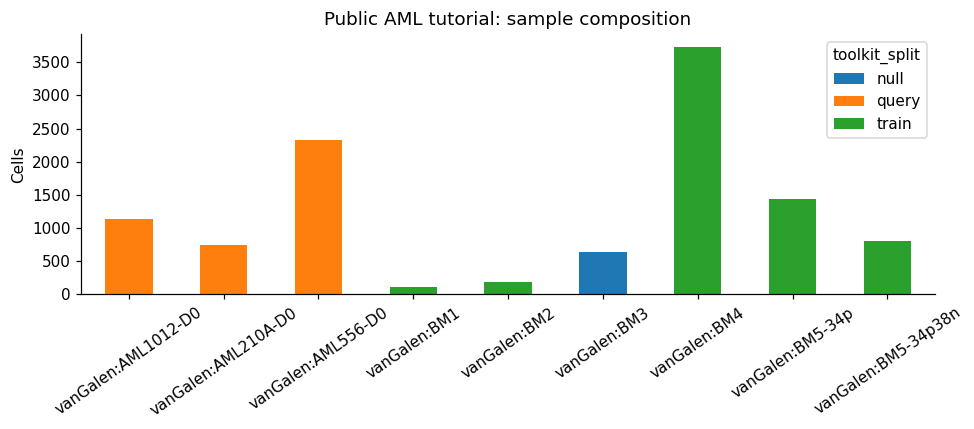

In [7]:
fig,ax=plt.subplots(figsize=(9,4))
obs.groupby(['sample','toolkit_split']).size().unstack(fill_value=0).plot.bar(stacked=True,ax=ax)
ax.set(ylabel='Cells',xlabel='',title='Public AML tutorial: sample composition'); ax.tick_params(axis='x',rotation=35)
fig.tight_layout(); fig.savefig(RESULTS/'sample_composition.png',dpi=160); plt.show()


## Train the learned hyperbolic reference
Only healthy training cells provide labels or influence training. The coarse supplied hierarchy supervises prototypes; measuring agreement with it later is not an independent validation of that hierarchy.


In [8]:
def make_rna(indices):
    return ad.AnnData(np.asarray(X[indices],dtype=np.float32),obs=obs.iloc[indices].copy())
reference = make_rna(train_idx)
def make_reference_loader(seed):
    torch.manual_seed(seed)
    return make_loader({'rna':reference},labels={'celltype':codes[train_idx]},batch_size=BATCH_SIZE,shuffle=True)
def make_config(geometry):
    return UniVIConfig(latent_dim=LATENT_DIM,
        modalities=[ModalityConfig('rna',X.shape[1],[128,64],[64,128])],
        latent_geometry=geometry,learn_curvature=(geometry!='euclidean'),
        prior='mog',prior_components=len(NAMES),prior_label_head='celltype',prior_tree_weight=2.0)
def train_model(geometry,seed):
    torch.manual_seed(seed); np.random.seed(seed)
    m=UniVIMultiModalVAE(make_config(geometry))
    m.set_hierarchy(tree_dist,root_index=NAMES.index(ROOT))
    hist=UniVITrainer(m,make_reference_loader(seed),
        train_cfg=TrainingConfig(n_epochs=N_EPOCHS,lr=1e-3,log_every=20)).fit()
    return m,hist
model,history=train_model('hyperbolic',SEED)
print('Learned curvature:',float(model.curvature))


[2026-11-11 15:54:55,084] [UniVITrainer] [INFO] TrainingConfig:
[2026-11-11 15:54:55,084] [UniVITrainer] [INFO]   n_epochs: 50
[2026-11-11 15:54:55,086] [UniVITrainer] [INFO]   batch_size: 256
[2026-11-11 15:54:55,086] [UniVITrainer] [INFO]   lr: 0.001
[2026-11-11 15:54:55,087] [UniVITrainer] [INFO]   weight_decay: 0.0
[2026-11-11 15:54:55,087] [UniVITrainer] [INFO]   device: 'cpu'
[2026-11-11 15:54:55,087] [UniVITrainer] [INFO]   log_every: 20
[2026-11-11 15:54:55,088] [UniVITrainer] [INFO]   grad_clip: None
[2026-11-11 15:54:55,088] [UniVITrainer] [INFO]   num_workers: 0
[2026-11-11 15:54:55,088] [UniVITrainer] [INFO]   seed: 0
[2026-11-11 15:54:55,089] [UniVITrainer] [INFO]   early_stopping: False
[2026-11-11 15:54:55,089] [UniVITrainer] [INFO]   patience: 20
[2026-11-11 15:54:55,090] [UniVITrainer] [INFO]   min_delta: 0.0
[2026-11-11 15:54:55,090] [UniVITrainer] [INFO]   best_epoch_warmup: 0
[2026-11-11 15:54:56,189] [UniVITrainer] [INFO] [Epoch 001] Train loss=14.0626 (beta=1.000,

Learned curvature: 0.596121072769165


C:\Users\ashfo\OneDrive\Desktop\UniVII\univii\models\univii.py:2332: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  return float(self.latent.curvature)


### Anchor and project
Anchoring moves the healthy root centroid to the origin without changing pairwise geometry. The model encodes every query in batches. Prototype agreement on healthy BM3 checks correspondence with existing annotations; agreement on training cells is a fit diagnostic.


In [9]:
def encode_indices(m,indices,anchored=False):
    m.eval(); device=next(m.parameters()).device
    pieces=[]
    with torch.no_grad():
        for start in range(0,len(indices),BATCH_SIZE):
            xx=torch.as_tensor(np.asarray(X[indices[start:start+BATCH_SIZE]],dtype=np.float32),device=device)
            pieces.append(m.encode_fused({'rna':xx},anchored=anchored)[0].detach().cpu().numpy())
    return np.concatenate(pieces) if pieces else np.empty((0,LATENT_DIM),dtype=np.float32)
root_idx=np.flatnonzero(train_mask & (labels==ROOT))
with torch.no_grad():
    model.set_latent_anchor(torch.as_tensor(encode_indices(model,root_idx),device=next(model.parameters()).device))
zfile=RESULTS/'latent_anchored.npy'
z=np.lib.format.open_memmap(zfile,mode='w+',dtype='float32',shape=(len(X),LATENT_DIM))
for start in range(0,len(X),10000):
    end=min(start+10000,len(X))
    z[start:end]=encode_indices(model,np.arange(start,end),anchored=True)
    if start%100000==0: print('Projected',end,'/',len(X))
z.flush()
assigned=np.empty(len(X),dtype=np.int64)
with torch.no_grad():
    for start in range(0,len(X),BATCH_SIZE):
        ii=np.arange(start,min(start+BATCH_SIZE,len(X)))
        raw=torch.as_tensor(encode_indices(model,ii),device=next(model.parameters()).device)
        assigned[ii]=model.prior_responsibilities(raw).argmax(1).cpu().numpy()
obs['prototype_label']=np.asarray(NAMES)[assigned]
obs.to_csv(RESULTS/'cell_metadata_and_predictions.csv.gz',compression='gzip')
for name,mask in [('train',train_mask),('null',null_mask),('query',query_mask)]:
    valid=mask & (codes>=0)
    print(name,'annotated cells:',valid.sum(),'prototype agreement:',np.mean(assigned[valid]==codes[valid]) if valid.any() else np.nan)
torch.save({'state_dict':model.state_dict(),'geometry':'hyperbolic','latent_dim':LATENT_DIM,
            'input_dim':X.shape[1],'parents':PARENTS,'seed':SEED},RESULTS/'hyperbolic_reference.pt')


Projected 10000 / 11127
train annotated cells: 6272 prototype agreement: 0.8917410714285714
null annotated cells: 643 prototype agreement: 0.749611197511664
query annotated cells: 830 prototype agreement: 0.6421686746987951


### Learned prototypes in the anchored space
The crosses are the learned mixture-prior centres, transformed using the same root anchor as the cells. Their names follow the supervised class order. Cells are the held-out healthy donor; their labels did not train these centres. Only the first two tangent coordinates are shown, so apparent overlap does not imply equality in the full latent space.


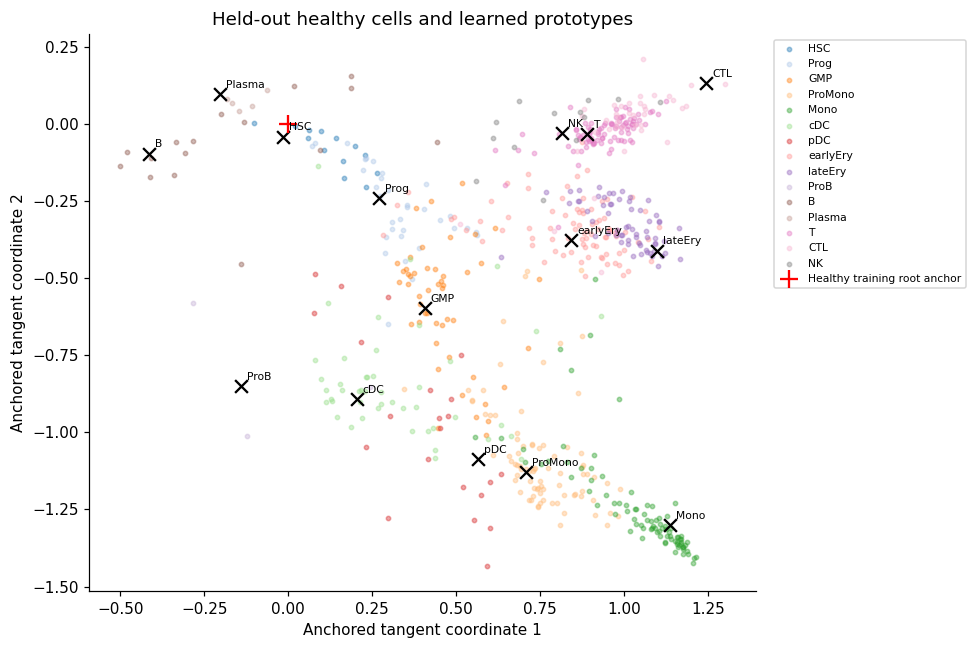

In [10]:
with torch.no_grad():centres=model.prior_centres().detach().cpu().numpy()
fig,ax=plt.subplots(figsize=(9,6))
for j,name in enumerate(NAMES):
    ii=null_idx[labels[null_idx]==name]
    ax.scatter(z[ii,0],z[ii,1],s=8,alpha=.4,color=plt.get_cmap('tab20')(j),label=name)
    ax.scatter(centres[j,0],centres[j,1],marker='x',s=70,color='black')
    ax.annotate(name,(centres[j,0],centres[j,1]),xytext=(4,4),textcoords='offset points',fontsize=7)
ax.scatter(0,0,marker='+',s=130,color='red',label='Healthy training root anchor')
ax.set(title='Held-out healthy cells and learned prototypes',xlabel='Anchored tangent coordinate 1',ylabel='Anchored tangent coordinate 2')
ax.legend(bbox_to_anchor=(1.02,1),loc='upper left',fontsize=7);fig.tight_layout()
fig.savefig(RESULTS/'prototype_overlay.png',dpi=160);plt.show()


## 2. Read the latent space
First two tangent coordinates show broad structure but do not preserve every distance of the 8D hyperbolic representation. Colors show supplied annotations and sample identity. Unknown AML lineage labels stay unknown.

Graph pseudotime is computed on a bounded subset rooted at healthy training HSCs. UniVII connects disconnected graph components with shortest connecting edges, so finite pseudotime is not proof of biological continuity. It does not establish elapsed time or clonal evolution.


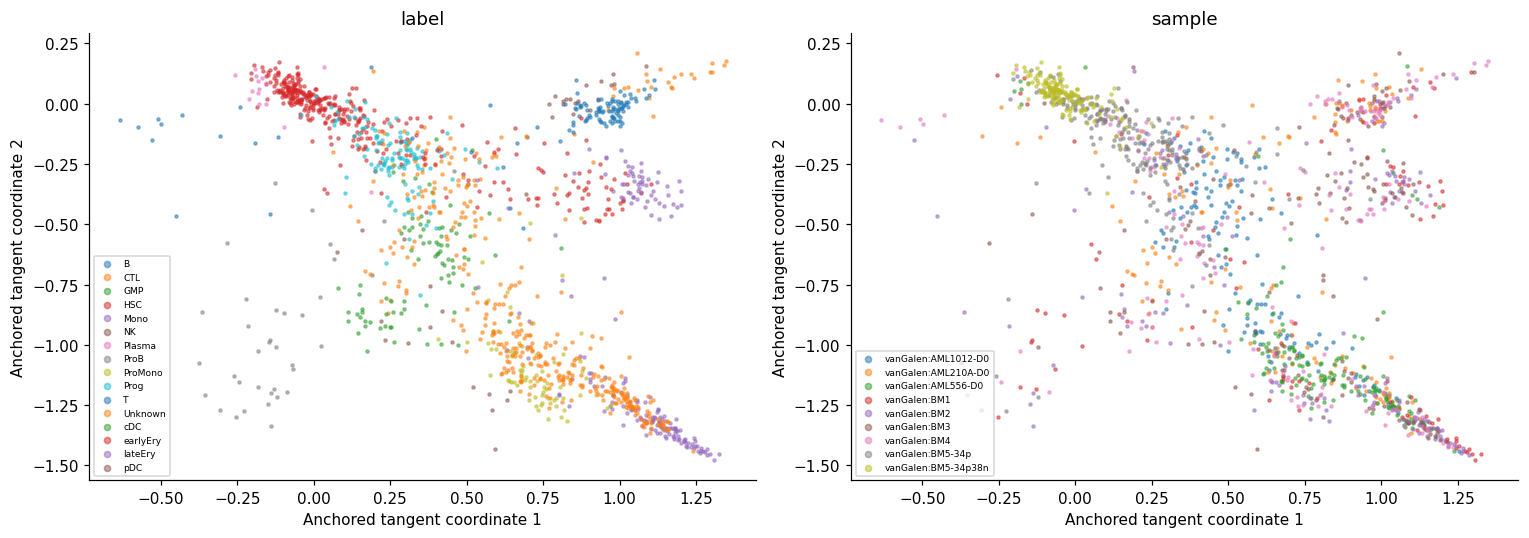

Healthy null inferred parents: {'HSC': None, 'Prog': 'HSC', 'earlyEry': 'Prog', 'GMP': 'Prog', 'NK': 'Prog', 'ProB': 'Prog', 'pDC': 'ProB', 'B': 'ProB', 'Plasma': 'B', 'CTL': 'NK', 'T': 'CTL', 'ProMono': 'GMP', 'cDC': 'GMP', 'Mono': 'ProMono', 'lateEry': 'earlyEry'}
Agreement with supplied prior: {'edge_jaccard': 0.75, 'path_spearman': 0.8087981092822146, 'parent_accuracy': 0.8}
Finite pseudotime: 1430 / 1430


label
HSC         0.000000
Prog        0.215906
earlyEry    1.111931
pDC         1.333000
B           1.713449
GMP         1.830265
ProB        1.953312
T           2.139340
NK          2.414707
CTL         2.506505
Unknown     2.773720
lateEry     2.815280
ProMono     2.983134
Plasma      3.083490
cDC         3.132251
Mono        3.775874
Name: graph_pseudotime, dtype: float64

In [11]:
rng=np.random.default_rng(SEED)
# Equal per-cohort quotas prevent the largest query cohort from occupying every plot point.
groups=list(obs.groupby('sample',sort=True).indices.values())
quota=max(1,(MAX_GRAPH_CELLS-100)//max(1,len(groups)))
plot_idx=np.unique(np.concatenate([rng.choice(v,min(len(v),quota),replace=False) for v in groups]+[root_idx[:100]]))
if len(plot_idx)>MAX_GRAPH_CELLS:
    keep=np.setdiff1d(plot_idx,root_idx[:100]); plot_idx=np.r_[root_idx[:100],rng.choice(keep,MAX_GRAPH_CELLS-len(root_idx[:100]),replace=False)]
zplot=np.asarray(z[plot_idx]); plot_labels=labels[plot_idx]
fig,axs=plt.subplots(1,2,figsize=(14,5))
for ax,col in zip(axs,['label','sample']):
    values=obs.iloc[plot_idx][col].to_numpy()
    for name in sorted(set(values)):
        use=values==name; ax.scatter(zplot[use,0],zplot[use,1],s=4,alpha=.5,label=name)
    ax.set(xlabel='Anchored tangent coordinate 1',ylabel='Anchored tangent coordinate 2',title=col)
    ax.legend(fontsize=6,markerscale=2,loc='best')
fig.tight_layout(); fig.savefig(RESULTS/'latent_overview.png',dpi=200); plt.show()
geo=dict(geometry=model.latent_geometry,hyperbolic_dim=model.latent.hyperbolic_dim,curvature=float(model.curvature))
# Use only held-out healthy cells for comparison with the supplied normal hierarchy.
valid_null=null_idx[codes[null_idx]>=0]
if ROOT in set(labels[valid_null]):
    recovered=cluster_tree(np.asarray(z[valid_null]),labels[valid_null],root=ROOT,**geo)
    print('Healthy null inferred parents:',recovered['parents'])
    if set(labels[valid_null])==set(NAMES): print('Agreement with supplied prior:',tree_agreement(recovered['parents'],PARENTS))
    else: print('Some prior labels absent in null donor; full-tree agreement skipped.')
pseudotime=graph_pseudotime(zplot,train_mask[plot_idx] & (plot_labels==ROOT),k=15,**geo)
pt=obs.iloc[plot_idx].copy(); pt['graph_pseudotime']=pseudotime
pt.to_csv(RESULTS/'sampled_graph_pseudotime.csv')
print('Finite pseudotime:',np.isfinite(pseudotime).sum(),'/',len(pseudotime))
display(pt.groupby('label')['graph_pseudotime'].median().sort_values())


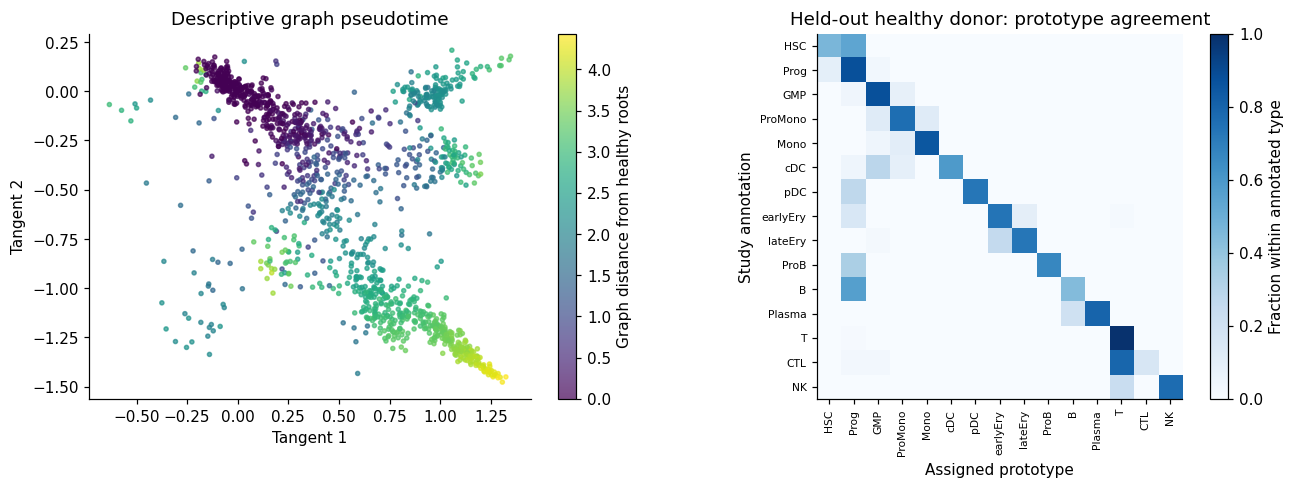

In [12]:
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
scat=axs[0].scatter(zplot[:,0],zplot[:,1],c=pseudotime,s=7,cmap='viridis',alpha=.7)
fig.colorbar(scat,ax=axs[0],label='Graph distance from healthy roots')
axs[0].set(title='Descriptive graph pseudotime',xlabel='Tangent 1',ylabel='Tangent 2')
normal=obs.loc[null_mask,['label','prototype_label']]
conf=pd.crosstab(normal['label'],normal['prototype_label']).reindex(index=NAMES,columns=NAMES,fill_value=0)
row_n=conf.sum(axis=1); fractions=conf.div(row_n.replace(0,np.nan),axis=0)
im=axs[1].imshow(fractions.to_numpy(),vmin=0,vmax=1,cmap='Blues')
axs[1].set(xticks=range(len(NAMES)),xticklabels=NAMES,yticks=range(len(NAMES)),yticklabels=NAMES,
           title='Held-out healthy donor: prototype agreement',xlabel='Assigned prototype',ylabel='Study annotation')
axs[1].tick_params(axis='x',rotation=90,labelsize=7);axs[1].tick_params(axis='y',labelsize=7)
fig.colorbar(im,ax=axs[1],label='Fraction within annotated type')
fig.tight_layout();fig.savefig(RESULTS/'pseudotime_and_confusion.png',dpi=180);plt.show()
conf.to_csv(RESULTS/'heldout_confusion_counts.csv')


### Segment a normal myeloid ordering
The HMM groups healthy HSC → Prog → GMP → ProMono → Mono cells along the estimated graph ordering. These are descriptive expression states, not proven temporal transitions. Restricting the example to one branch avoids ordering all lymphoid and myeloid cells as a single trajectory.


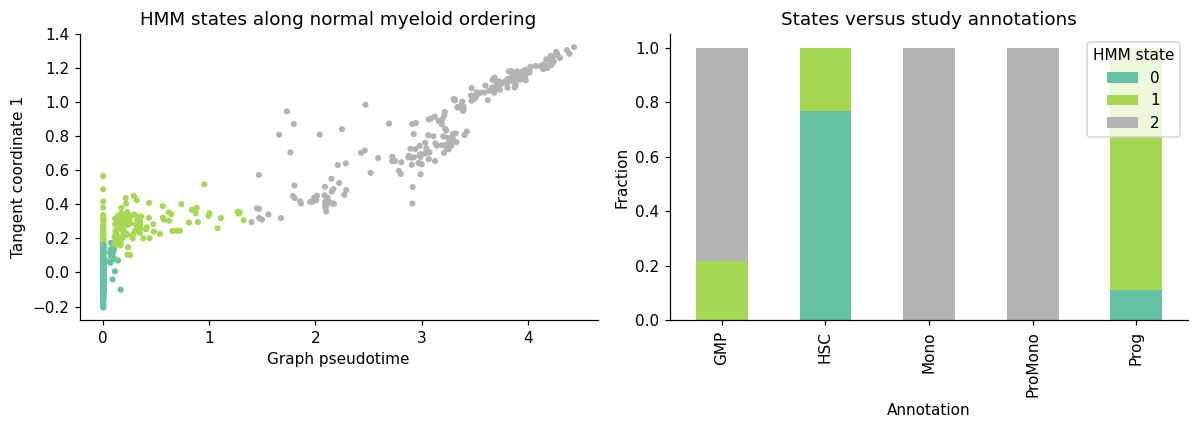

In [13]:
from univii.hmm import segment_by_order
lineage=np.isin(plot_labels,['HSC','Prog','GMP','ProMono','Mono']) & (train_mask| null_mask)[plot_idx] & np.isfinite(pseudotime)
if lineage.sum()>=30:
    states,probs,hmm=segment_by_order(zplot[lineage],order=pseudotime[lineage],n_states=3,n_iter=100)
    fig,axs=plt.subplots(1,2,figsize=(11,4))
    axs[0].scatter(pseudotime[lineage],zplot[lineage,0],c=states,cmap='Set2',s=9)
    axs[0].set(xlabel='Graph pseudotime',ylabel='Tangent coordinate 1',title='HMM states along normal myeloid ordering')
    ct=pd.crosstab(pd.Series(plot_labels[lineage],name='Annotation'),pd.Series(states,name='HMM state'),normalize='index')
    ct.plot.bar(stacked=True,ax=axs[1],colormap='Set2');axs[1].set(ylabel='Fraction',title='States versus study annotations')
    fig.tight_layout();fig.savefig(RESULTS/'hmm_states.png',dpi=180);plt.show()
else: print('Not enough normal myeloid cells in the graph subset for HMM analysis.')


## Matched geometry comparison across seeds

`compare_models` and `summarize` train Euclidean, hyperbolic and product variants at the same dimension, with the same reference cells, prior supervision and epoch budget. Three seeds per geometry give nine runs. All metrics below use the held-out healthy donor: prototype annotation agreement, label-neighbour purity, and Spearman correlation between geometry-aware centroid distances and the supplied tree distances. Training time and parameter counts are also recorded.

Tree agreement measures consistency with a **training prior**, not independently verified lineage truth. Seed SD measures training variability, not uncertainty across donors. These short runs demonstrate the comparison API; selecting a geometry on BM3 would require a new donor for final confirmation. Set `RUN_GEOMETRY_SWEEP=False` to shorten a rerun.


[2026-11-11 15:55:54,258] [UniVITrainer] [INFO] TrainingConfig:
[2026-11-11 15:55:54,259] [UniVITrainer] [INFO]   n_epochs: 50
[2026-11-11 15:55:54,260] [UniVITrainer] [INFO]   batch_size: 256
[2026-11-11 15:55:54,261] [UniVITrainer] [INFO]   lr: 0.001
[2026-11-11 15:55:54,262] [UniVITrainer] [INFO]   weight_decay: 0.0
[2026-11-11 15:55:54,262] [UniVITrainer] [INFO]   device: 'cpu'
[2026-11-11 15:55:54,262] [UniVITrainer] [INFO]   log_every: 20
[2026-11-11 15:55:54,263] [UniVITrainer] [INFO]   grad_clip: None
[2026-11-11 15:55:54,263] [UniVITrainer] [INFO]   num_workers: 0
[2026-11-11 15:55:54,264] [UniVITrainer] [INFO]   seed: 0
[2026-11-11 15:55:54,264] [UniVITrainer] [INFO]   early_stopping: False
[2026-11-11 15:55:54,264] [UniVITrainer] [INFO]   patience: 20
[2026-11-11 15:55:54,264] [UniVITrainer] [INFO]   min_delta: 0.0
[2026-11-11 15:55:54,265] [UniVITrainer] [INFO]   best_epoch_warmup: 0
[2026-11-11 15:55:54,494] [UniVITrainer] [INFO] [Epoch 001] Train loss=14.7237 (beta=1.000,

n_seeds n_parameters      train_seconds           final_train_loss  \
                           mean  std          mean       std             mean   
variant                                                                         
euclidean        3      31809.0  0.0     11.196199  0.102921         3.996293   
hyperbolic       3      31810.0  0.0     49.186472  4.470528         3.321257   
product          3      31810.0  0.0     50.624507  1.189635         3.352913   

                     tree_spearman           label_purity            \
                 std          mean       std         mean       std   
variant                                                               
euclidean   0.352926      0.776440  0.070476     0.730914  0.012966   
hyperbolic  0.155988      0.854941  0.039113     0.746017  0.004330   
product     0.069043      0.832494  0.042805     0.735545  0.005758   

           null_annotation_agreement           curvature            \
                                mean       std      mean       std   
variant                                                              
euclidean                   0.738206  0.022122  1.000000  0.000000   
hyperbolic                  0.760498  0.009712  0.626929  0.027077   
product                     0.741835  0.020337  1.305406  0.067776   

           evaluated_cells       
                      mean  std  
variant                          
euclidean            643.0  0.0  
hyperbolic           643.0  0.0  
product              643.0  0.0

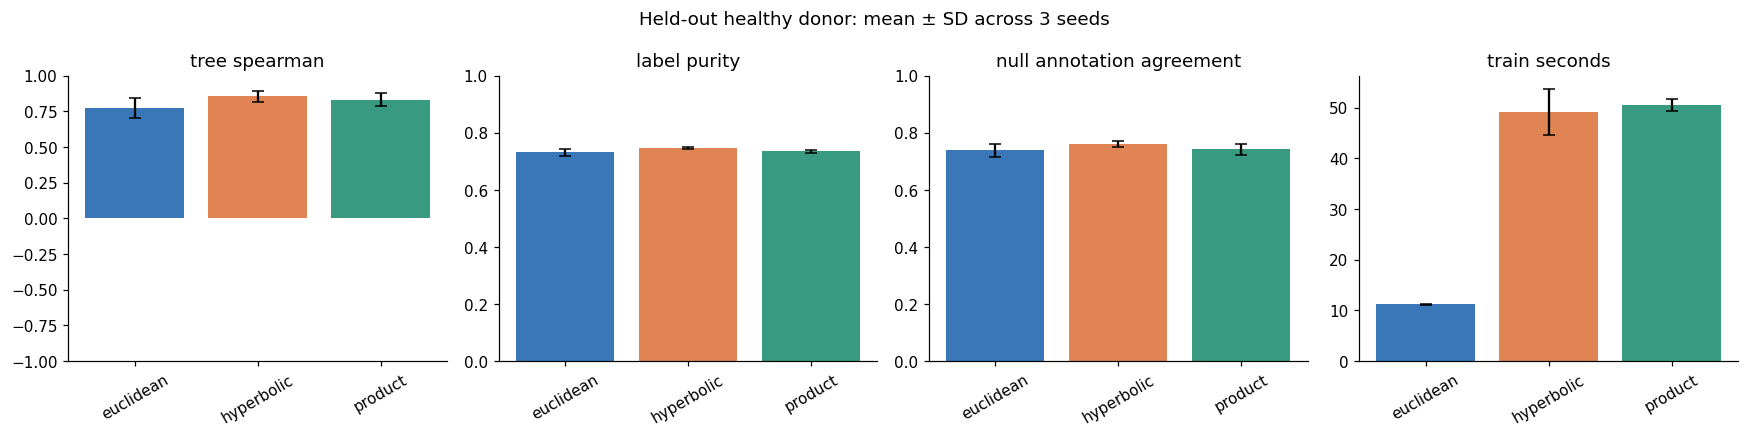

In [14]:
from scipy.stats import spearmanr
from univii.experiments import compare_models, summarize
from univii.hierarchy import cluster_centroids
from univii.geometry import pairwise_latent_distance
from univii.atlas import label_purity
def evaluate_geometry(m):
    valid_idx=null_idx[codes[null_idx]>=0]
    zz=encode_indices(m,valid_idx)
    g=dict(geometry=m.latent_geometry,hyperbolic_dim=m.latent.hyperbolic_dim,curvature=float(m.curvature))
    cent,names=cluster_centroids(zz,labels[valid_idx],**g)
    distances=pairwise_latent_distance(cent,**g)
    order=[NAMES.index(v) for v in names];upper=np.triu_indices(len(names),1)
    target=tree_dist[np.ix_(order,order)]
    with torch.no_grad():
        predicted=m.prior_responsibilities(torch.as_tensor(zz,device=next(m.parameters()).device)).argmax(1).cpu().numpy()
    return {'tree_spearman':float(spearmanr(distances[upper],target[upper]).statistic),
            'label_purity':label_purity(zz,labels[valid_idx],**g),
            'null_annotation_agreement':float((predicted==codes[valid_idx]).mean()),
            'curvature':float(m.curvature),'evaluated_cells':len(valid_idx)}
if RUN_GEOMETRY_SWEEP:
    variants={g:make_config(g) for g in ['euclidean','hyperbolic','product']}
    runs=compare_models(variants,make_reference_loader,evaluate=evaluate_geometry,seeds=SEEDS,
        train_cfg=TrainingConfig(n_epochs=N_EPOCHS,lr=1e-3,log_every=20),
        setup=lambda m:m.set_hierarchy(tree_dist,root_index=NAMES.index(ROOT)))
    runs.to_csv(RESULTS/'geometry_comparison.csv',index=False)
    comparison=summarize(runs);display(comparison)
    comparison.to_csv(RESULTS/'geometry_summary.csv')
    metrics=['tree_spearman','label_purity','null_annotation_agreement','train_seconds']
    fig,axs=plt.subplots(1,4,figsize=(16,4))
    for ax,metric in zip(axs,metrics):
        summary=runs.groupby('variant',sort=False)[metric].agg(['mean','std'])
        ax.bar(summary.index,summary['mean'],yerr=summary['std'],capsize=4,color=['#3977b8','#df8452','#389a80'])
        ax.set_title(metric.replace('_',' '));ax.tick_params(axis='x',rotation=30)
        if metric=='tree_spearman':ax.set_ylim(-1,1)
        elif metric!='train_seconds':ax.set_ylim(0,1)
    fig.suptitle('Held-out healthy donor: mean ± SD across 3 seeds');fig.tight_layout()
    fig.savefig(RESULTS/'geometry_comparison.png',dpi=170);plt.show()
else: print('Geometry comparison disabled.')


## 3. A genuine paired-assay mosaic example

We download the **10x Genomics 5k PBMC RNA + surface-protein assay** as the scvi-tools filtered public copy (3,994 cells, 29 proteins), keeping its measured barcode pairing. The GitHub data revision and SHA-256 are pinned; this avoids relying on an unversioned processed file. After filtering zero-library cells, a seeded split creates three disjoint groups: RNA-only, ADT-only, and a paired bridge. Hidden modalities are excluded from preprocessing fits and from training loaders. Their measured values are used only for diagnostic marker coloring after training.

This is a **transductive missing-modality demonstration within one assay**: every cell enters atlas training through its available modality. It is not a donor-held-out generalization benchmark. We do not invent cell-type truth; CD3/CD19/CD14 overlays show measured protein patterns, including proteins hidden from RNA-only cells during training. No annotation labels supervise this atlas.

RNA uses library normalization → log1p → 1,000 variable genes → 30 PCs, fitted only on RNA-observed groups. ADT uses per-cell log-ratio normalization and feature scaling fitted only on ADT-observed groups. Both are continuous Gaussian inputs.


In [15]:
from scipy import sparse
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import urllib.request, shutil, hashlib, h5py

def fetch_file(url,path,expected_sha256=None):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    if not path.exists():
        part=path.with_suffix(path.suffix+'.part')
        with urllib.request.urlopen(url,timeout=120) as response,open(part,'wb') as out:
            shutil.copyfileobj(response,out)
        part.replace(path)
    digest=sha256(path)
    if expected_sha256 and digest!=expected_sha256: raise ValueError('Checksum mismatch: '+str(path))
    return path,digest

if RUN_MOSAIC:
    PBMC_URL='https://raw.githubusercontent.com/YosefLab/scVI-data/c6d4b81cd0597d54d2a9a920066e2527867e4b5e/pbmc_5k_protein_v3.h5ad'
    pbmc_path,pbmc_sha=fetch_file(PBMC_URL,CACHE/'pbmc5k.h5ad','a1bf51e070d24b39627ea4de9b3e489a4637ff795e1061e0733e26c3baec8847')
    pbmc=ad.read_h5ad(pbmc_path)
    rcounts=sparse.csr_matrix(pbmc.X,dtype=np.float32)
    acounts=np.asarray(pbmc.obsm['protein_expression'],dtype=np.float32)
    protein_names=np.asarray(pbmc.uns['protein_names']).astype(str)
    barcodes=pbmc.obs_names.to_numpy().astype(str)
    if not pbmc.obs_names.is_unique: raise ValueError('Duplicate paired PBMC barcodes')
    if acounts.shape!=(pbmc.n_obs,len(protein_names)): raise ValueError('Protein alignment mismatch')
    for values in [rcounts.data,acounts]:
        if not np.isfinite(values).all() or (values<0).any() or not np.allclose(values,np.round(values)): raise ValueError('Expected raw PBMC counts')
    keep=(np.asarray(rcounts.sum(1)).ravel()>0)&(acounts.sum(1)>0)
    rcounts=rcounts[keep];acounts=acounts[keep];barcodes=barcodes[keep]
    rng_m=np.random.default_rng(SEED); perm=rng_m.permutation(len(barcodes)); n=len(perm)
    a,b,c=np.split(perm,[int(.35*n),int(.70*n)])
    rfit=np.r_[a,c];pfit=np.r_[b,c]
    rn=sparse.diags(1e4/np.asarray(rcounts.sum(1)).ravel())@rcounts;rn=rn.tocsr();rn.data=np.log1p(rn.data)
    mu=np.asarray(rn[rfit].mean(0)).ravel();var=np.asarray(rn[rfit].power(2).mean(0)).ravel()-mu**2
    hv=np.argsort(var)[-min(1000,(var>0).sum()):]
    rna_pca=PCA(n_components=30,random_state=SEED,svd_solver='randomized').fit(rn[rfit][:,hv].toarray())
    rp=rna_pca.transform(rn[:,hv].toarray());rna_scale=np.sqrt(np.mean(rp[rfit]**2));rp=(rp/rna_scale).astype(np.float32)
    ap=np.log1p(acounts);ap-=ap.mean(axis=1,keepdims=True)
    adt_scaler=StandardScaler().fit(ap[pfit]);ap=adt_scaler.transform(ap).astype(np.float32)
    rna=ad.AnnData(rp,obs=pd.DataFrame(index=barcodes))
    adt=ad.AnnData(ap,obs=pd.DataFrame(index=barcodes),var=pd.DataFrame(index=protein_names))
    print('Paired assay:',n,'cells;',rcounts.shape[1],'RNA genes;',len(protein_names),'proteins')
    print('RNA-only:',len(a),'ADT-only:',len(b),'bridge:',len(c))
    (RESULTS/'pbmc_source.json').write_text(json.dumps({'url':PBMC_URL,'sha256':pbmc_sha},indent=2))


Paired assay: 3994 cells; 16581 RNA genes; 29 proteins
RNA-only: 1397 ADT-only: 1398 bridge: 1199


In [16]:
if RUN_MOSAIC:
    from univii import presets
    from univii.atlas import make_mosaic_loader,encode_cohort,cohort_mixing
    cohorts={'RNA only':{'rna':rna[a].copy()},'ADT only':{'adt':adt[b].copy()},
             'Paired bridge':{'rna':rna[c].copy(),'adt':adt[c].copy()}}
    mosaic=make_mosaic_loader(cohorts,batch_size=128,ratios=[1,1,2],seed=SEED)
    torch.manual_seed(SEED)
    atlas_cfg=presets.atlas_config({'rna':rp.shape[1],'adt':ap.shape[1]},n_cohorts=3,latent_dim=8,cycle_weight=1.0)
    atlas=UniVIMultiModalVAE(atlas_cfg)
    atlas_history=UniVITrainer(atlas,mosaic,train_cfg=TrainingConfig(n_epochs=N_EPOCHS,lr=1e-3,log_every=5)).fit()
    z_by_cohort={name:encode_cohort(atlas,data,cohort=mosaic.cohort_codes[name]) for name,data in cohorts.items()}
    z_atlas=np.vstack(list(z_by_cohort.values()))
    cell_order=np.r_[a,b,c]
    cohort_of=np.repeat(list(cohorts),[len(a),len(b),len(c)])
    # One shared PCA projection of the learned 8D atlas; no separately fitted panel coordinates.
    atlas_view=PCA(n_components=2,random_state=SEED)
    uv=atlas_view.fit_transform(z_atlas)
    np.save(RESULTS/'mosaic_latent.npy',z_atlas)
    pd.DataFrame({'barcode':barcodes[cell_order],'observed_modalities':cohort_of,'view1':uv[:,0],'view2':uv[:,1]}).to_csv(RESULTS/'mosaic_cells.csv',index=False)
    print('Latent variance shown by 2D PCA:',atlas_view.explained_variance_ratio_.sum())
    print('Descriptive cohort mixing:',cohort_mixing(z_atlas,cohort_of))


[2026-11-11 16:01:29,745] [UniVITrainer] [INFO] TrainingConfig:
[2026-11-11 16:01:29,746] [UniVITrainer] [INFO]   n_epochs: 50
[2026-11-11 16:01:29,747] [UniVITrainer] [INFO]   batch_size: 256
[2026-11-11 16:01:29,747] [UniVITrainer] [INFO]   lr: 0.001
[2026-11-11 16:01:29,748] [UniVITrainer] [INFO]   weight_decay: 0.0
[2026-11-11 16:01:29,748] [UniVITrainer] [INFO]   device: 'cpu'
[2026-11-11 16:01:29,749] [UniVITrainer] [INFO]   log_every: 5
[2026-11-11 16:01:29,749] [UniVITrainer] [INFO]   grad_clip: None
[2026-11-11 16:01:29,749] [UniVITrainer] [INFO]   num_workers: 0
[2026-11-11 16:01:29,750] [UniVITrainer] [INFO]   seed: 0
[2026-11-11 16:01:29,750] [UniVITrainer] [INFO]   early_stopping: False
[2026-11-11 16:01:29,750] [UniVITrainer] [INFO]   patience: 20
[2026-11-11 16:01:29,750] [UniVITrainer] [INFO]   min_delta: 0.0
[2026-11-11 16:01:29,751] [UniVITrainer] [INFO]   best_epoch_warmup: 0
[2026-11-11 16:01:31,601] [UniVITrainer] [INFO] [Epoch 001] Train loss=31.0568 (beta=1.000, 

Latent variance shown by 2D PCA: 0.68427956
Descriptive cohort mixing: 0.9071091891533295


### How to read the mosaic atlas
The same joint coordinates appear in each panel. Mixed colors can indicate alignment of measurement groups, but mixing alone can also occur after loss of biological structure. The protein overlays help inspect whether marker-associated variation is retained. These are measured markers, not inferred cell types or independent validation labels.

The final panels isolate each modality group with identical axis limits. RNA-only cells never supplied ADT during training; the bridge gives the model paired measurements needed to relate modalities.


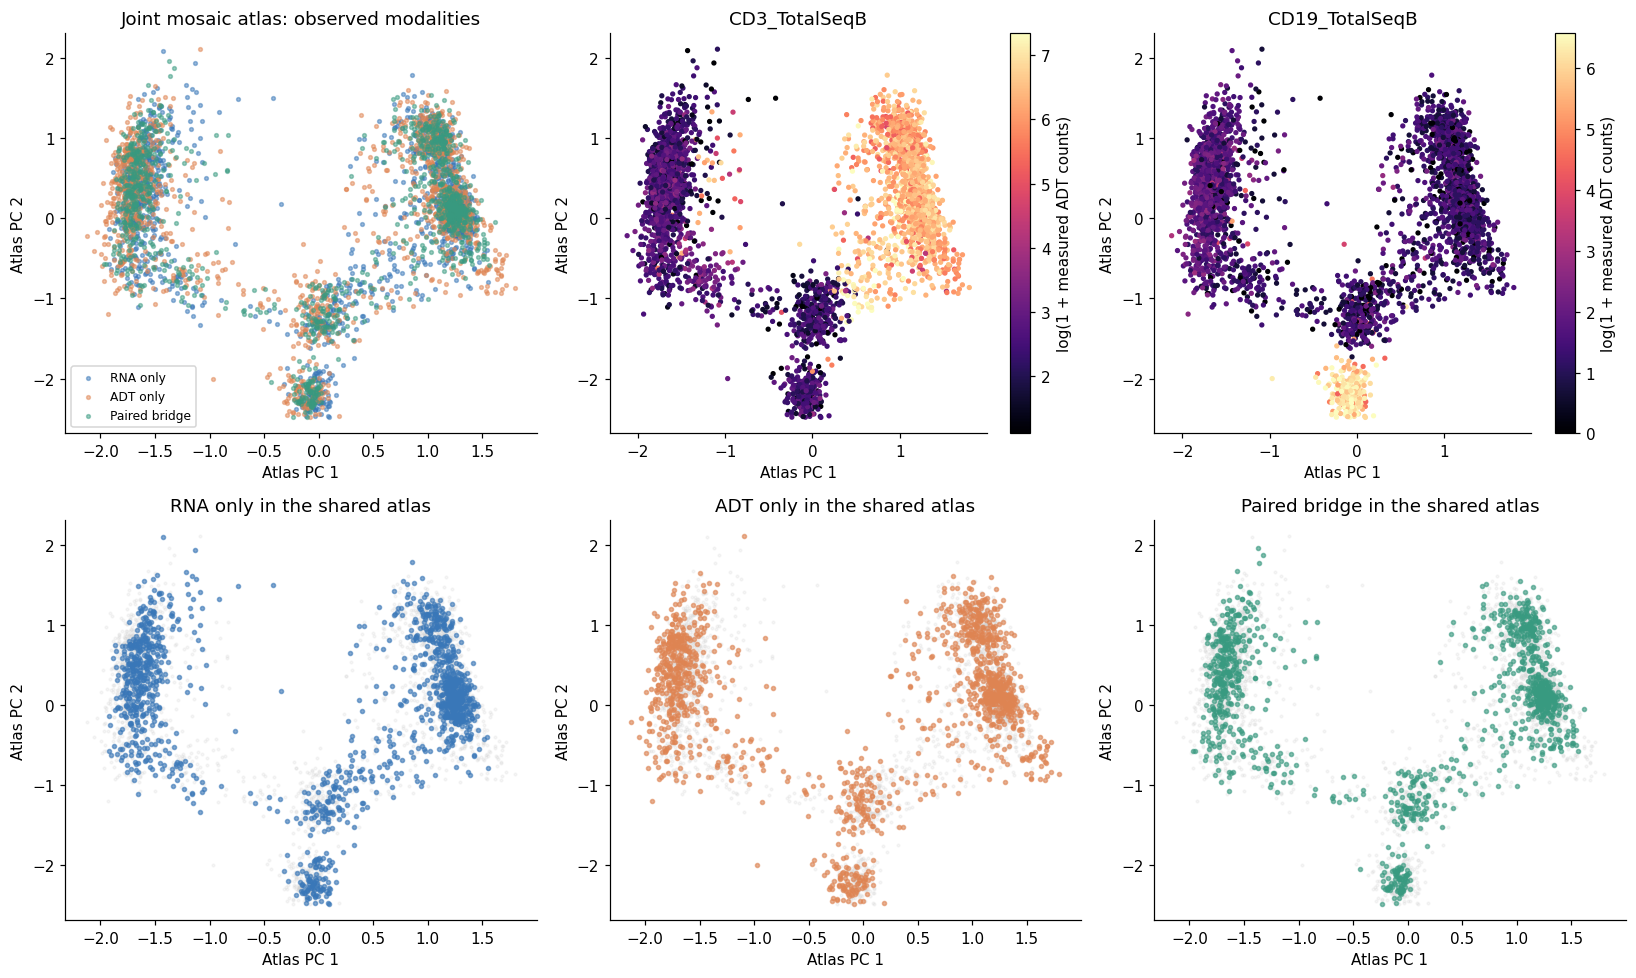

In [17]:
if RUN_MOSAIC:
    fig,axs=plt.subplots(2,3,figsize=(15,9))
    palette={'RNA only':'#3977b8','ADT only':'#df8452','Paired bridge':'#389a80'}
    for name in cohorts:
        use=cohort_of==name;axs[0,0].scatter(uv[use,0],uv[use,1],s=6,alpha=.5,c=palette[name],label=name)
    axs[0,0].legend(fontsize=8);axs[0,0].set_title('Joint mosaic atlas: observed modalities')
    marker_indices=[]
    for marker in ['CD3','CD19']:
        hits=[i for i,p in enumerate(protein_names) if str(p).split('_')[0].split('-')[0]==marker]
        if not hits: hits=[i for i,p in enumerate(protein_names) if marker in str(p)]
        marker_indices.append(hits[0] if hits else None)
    for ax,marker,mi in zip(axs[0,1:],['CD3','CD19'],marker_indices):
        if mi is not None:
            vals=np.log1p(acounts[cell_order,mi]);im=ax.scatter(uv[:,0],uv[:,1],c=vals,cmap='magma',s=6,vmin=np.percentile(vals,1),vmax=np.percentile(vals,99))
            fig.colorbar(im,ax=ax,label='log(1 + measured ADT counts)')
            ax.set_title(str(protein_names[mi]))
        else: ax.text(.5,.5,marker+' unavailable',ha='center',transform=ax.transAxes)
    for ax,name in zip(axs[1],cohorts):
        ax.scatter(uv[:,0],uv[:,1],s=3,c='lightgray',alpha=.2)
        use=cohort_of==name;ax.scatter(uv[use,0],uv[use,1],s=7,c=palette[name],alpha=.6)
        ax.set_title(name+' in the shared atlas')
    for ax in axs.flat:
        ax.set(xlabel='Atlas PC 1',ylabel='Atlas PC 2',xlim=(uv[:,0].min()-.2,uv[:,0].max()+.2),ylim=(uv[:,1].min()-.2,uv[:,1].max()+.2))
    fig.tight_layout();fig.savefig(RESULTS/'mosaic_atlas.png',dpi=180);plt.show()


## 4. Annotated bridge transfer on real CITE-seq cells

The PBMC atlas above remains unchanged. For quantitative label transfer we add **SLN111**, a public mouse spleen/lymph-node CITE-seq dataset used in the totalVI study. It includes the authors' `cell_types` annotations, paired RNA/protein measurements, and recorded batches `SLN111-D1` and `SLN111-D2`. These identifiers are treated as **batches**, not assumed to be donor IDs.

We use a seeded subset of D1 to create disjoint RNA-only, ADT-only and paired-bridge groups. Preprocessing learns from observed modalities of D1 only. Published doublet/low-quality annotations are excluded explicitly. Cell-type annotations do **not** train this atlas; only bridge labels are supplied to the post-training nearest-neighbour label-transfer step. RNA-only and ADT-only labels are reserved for evaluation.

This measures agreement with existing study annotations, which were derived computationally using expression/protein data; it is not independent ground truth. Modality masking is deliberate, but every count and annotation comes from real cells. The pinned source file is approximately 67 MB; the actual download size is printed.

Sources: [scvi-tools dataset documentation](https://docs.scvi-tools.org/en/stable/api/reference/scvi.data.spleen_lymph_cite_seq.html), [study annotation procedure](https://github.com/YosefLab/totalVI_reproducibility/blob/master/spleen_lymph_all/add_annotations_to_anndatas.py), [totalVI paper](https://doi.org/10.1038/s41592-020-01050-x).


In [18]:
if RUN_ANNOTATED_ATLAS:
    from univii import presets
    from univii.atlas import make_mosaic_loader,encode_cohort,transfer_labels,label_purity,cohort_mixing,adapt_to_cohort
    from sklearn.metrics import accuracy_score,f1_score,confusion_matrix
    SLN_URL='https://raw.githubusercontent.com/YosefLab/scVI-data/b6b6d862e44e97751377ca99e95ff29f3fbd3a43/sln_111.h5ad'
    sln_path,sln_hash=fetch_file(SLN_URL,CACHE/'sln_111.h5ad','2098ca88739a9d2d789cb092481c326d7bcbfa73ca815ce3e80b7668cffbe452')
    sln=ad.read_h5ad(sln_path)
    print('SLN download: %.1f MB' % (sln_path.stat().st_size/1e6))
    for col in ['cell_types','batch','tissue']:
        if col not in sln.obs:raise ValueError('Missing SLN annotation: '+col)
    annotation=sln.obs['cell_types'].astype('string')
    good=annotation.notna() & ~annotation.str.contains('doublet|low quality',case=False,regex=True,na=False)
    good &= np.asarray(sln.X.sum(1)).ravel()>0
    good &= np.asarray(sln.obsm['protein_expression']).sum(1)>0
    sln=sln[good.to_numpy()].copy()
    # Prefix batch identity because independent libraries may reuse cell barcodes.
    sln.obs_names=sln.obs['batch'].astype(str).to_numpy()+':'+sln.obs_names.astype(str)
    if not sln.obs_names.is_unique:raise ValueError('SLN IDs are not unique after adding batch identity.')
    rng_s=np.random.default_rng(SEED)
    ri=np.flatnonzero(sln.obs['batch'].astype(str).to_numpy()==REFERENCE_BATCH)
    qi=np.flatnonzero(sln.obs['batch'].astype(str).to_numpy()==NEW_BATCH)
    if len(ri)<100 or len(qi)<100:raise ValueError('Reference/new batches need at least 100 cells.')
    ri=rng_s.choice(ri,min(MAX_REFERENCE_CELLS,len(ri)),replace=False)
    qi=rng_s.choice(qi,min(MAX_NEW_CELLS,len(qi)),replace=False)
    sln=sln[np.r_[ri,qi]].copy();nr=len(ri)
    ref_perm=rng_s.permutation(nr)
    sr,sa,sb=np.split(ref_perm,[int(.35*nr),int(.70*nr)])
    new_perm=rng_s.permutation(np.arange(nr,sln.n_obs))
    adapt_idx,eval_idx=np.array_split(new_perm,2)
    assert not set(adapt_idx)&set(eval_idx)
    counts=sparse.csr_matrix(sln.X,dtype=np.float32)
    proteins=np.asarray(sln.obsm['protein_expression'],dtype=np.float32)
    for values in [counts.data,proteins]:
        if not np.isfinite(values).all() or (values<0).any() or not np.allclose(values,np.round(values)):raise ValueError('SLN inputs must be raw nonnegative counts.')
    s_rfit=np.r_[sr,sb];s_afit=np.r_[sa,sb]
    log_r=sparse.diags(1e4/np.asarray(counts.sum(1)).ravel())@counts;log_r=log_r.tocsr();log_r.data=np.log1p(log_r.data)
    mu=np.asarray(log_r[s_rfit].mean(0)).ravel();vv=np.asarray(log_r[s_rfit].power(2).mean(0)).ravel()-mu**2
    s_hv=np.argsort(vv)[-1000:]
    s_pca=PCA(n_components=30,random_state=SEED,svd_solver='randomized').fit(log_r[s_rfit][:,s_hv].toarray())
    s_rna=s_pca.transform(log_r[:,s_hv].toarray());s_scale=np.sqrt(np.mean(s_rna[s_rfit]**2));s_rna=(s_rna/s_scale).astype(np.float32)
    log_a=np.log1p(proteins);log_a-=log_a.mean(1,keepdims=True)
    s_scaler=StandardScaler().fit(log_a[s_afit]);s_adt=s_scaler.transform(log_a).astype(np.float32)
    # Loader inputs contain no annotations; the labels below are used only after training.
    s_r=ad.AnnData(s_rna,obs=pd.DataFrame(index=sln.obs_names))
    s_a=ad.AnnData(s_adt,obs=pd.DataFrame(index=sln.obs_names))
    s_labels=sln.obs['cell_types'].astype(str).to_numpy()
    s_cohorts={'RNA only':{'rna':s_r[sr].copy()},'ADT only':{'adt':s_a[sa].copy()},
               'Paired bridge':{'rna':s_r[sb].copy(),'adt':s_a[sb].copy()}}
    s_loader=make_mosaic_loader(s_cohorts,batch_size=128,ratios=[1,1,2],seed=SEED)
    torch.manual_seed(SEED)
    s_atlas=UniVIMultiModalVAE(presets.atlas_config({'rna':s_rna.shape[1],'adt':s_adt.shape[1]},n_cohorts=3,latent_dim=8,cycle_weight=1.0))
    s_history=UniVITrainer(s_atlas,s_loader,train_cfg=TrainingConfig(n_epochs=N_EPOCHS,lr=1e-3,log_every=5,seed=SEED)).fit()
    s_z={k:encode_cohort(s_atlas,v,cohort=s_loader.cohort_codes[k]) for k,v in s_cohorts.items()}
    s_order=np.r_[sr,sa,sb];s_joined=np.vstack(list(s_z.values()))
    s_group=np.repeat(list(s_cohorts),[len(sr),len(sa),len(sb)])
    s_view=PCA(n_components=2,random_state=SEED).fit(s_joined);s_xy=s_view.transform(s_joined)
    print('D1 cells:',nr,'D2 adaptation cells:',len(adapt_idx),'D2 evaluation cells:',len(eval_idx))
    print('Atlas label purity:',label_purity(s_joined,s_labels[s_order]))
    print('Atlas modality-group mixing:',cohort_mixing(s_joined,s_group))
    split=pd.Series('unused',index=sln.obs_names)
    for ids,name in [(sr,'reference_RNA'),(sa,'reference_ADT'),(sb,'reference_bridge'),(adapt_idx,'new_adaptation'),(eval_idx,'new_evaluation')]:split.iloc[ids]=name
    audit=sln.obs.copy();audit['toolkit_split']=split;audit.to_csv(RESULTS/'annotated_atlas_split.csv')
    (RESULTS/'sln_source.json').write_text(json.dumps({'url':SLN_URL,'sha256':sln_hash,'reference_batch':REFERENCE_BATCH,'new_batch':NEW_BATCH},indent=2))
    np.savez_compressed(RESULTS/'sln_preprocessing.npz',genes=sln.var_names[s_hv].to_numpy(dtype=str),pca_components=s_pca.components_,pca_mean=s_pca.mean_,rna_scale=s_scale,adt_mean=s_scaler.mean_,adt_scale=s_scaler.scale_)


SLN download: 66.7 MB


[2026-11-11 16:06:03,080] [UniVITrainer] [INFO] TrainingConfig:
[2026-11-11 16:06:03,081] [UniVITrainer] [INFO]   n_epochs: 50
[2026-11-11 16:06:03,082] [UniVITrainer] [INFO]   batch_size: 256
[2026-11-11 16:06:03,082] [UniVITrainer] [INFO]   lr: 0.001
[2026-11-11 16:06:03,083] [UniVITrainer] [INFO]   weight_decay: 0.0
[2026-11-11 16:06:03,083] [UniVITrainer] [INFO]   device: 'cpu'
[2026-11-11 16:06:03,083] [UniVITrainer] [INFO]   log_every: 5
[2026-11-11 16:06:03,084] [UniVITrainer] [INFO]   grad_clip: None
[2026-11-11 16:06:03,085] [UniVITrainer] [INFO]   num_workers: 0
[2026-11-11 16:06:03,085] [UniVITrainer] [INFO]   seed: 0
[2026-11-11 16:06:03,085] [UniVITrainer] [INFO]   early_stopping: False
[2026-11-11 16:06:03,086] [UniVITrainer] [INFO]   patience: 20
[2026-11-11 16:06:03,086] [UniVITrainer] [INFO]   min_delta: 0.0
[2026-11-11 16:06:03,086] [UniVITrainer] [INFO]   best_epoch_warmup: 0
[2026-11-11 16:06:04,969] [UniVITrainer] [INFO] [Epoch 001] Train loss=70.0369 (beta=1.000, 

D1 cells: 4000 D2 adaptation cells: 800 D2 evaluation cells: 800
Atlas label purity: 0.6461166666666667
Atlas modality-group mixing: 0.9393223443223443


,cells,accuracy,macro_f1,label_purity,bridge_label_coverage,mean_confidence,median_novelty
group,,,,,,,
RNA only,1400,0.732857,0.340223,0.637000,0.997857,0.745810,1.088741
ADT only,1400,0.738571,0.385296,0.627143,0.994286,0.761048,1.268934


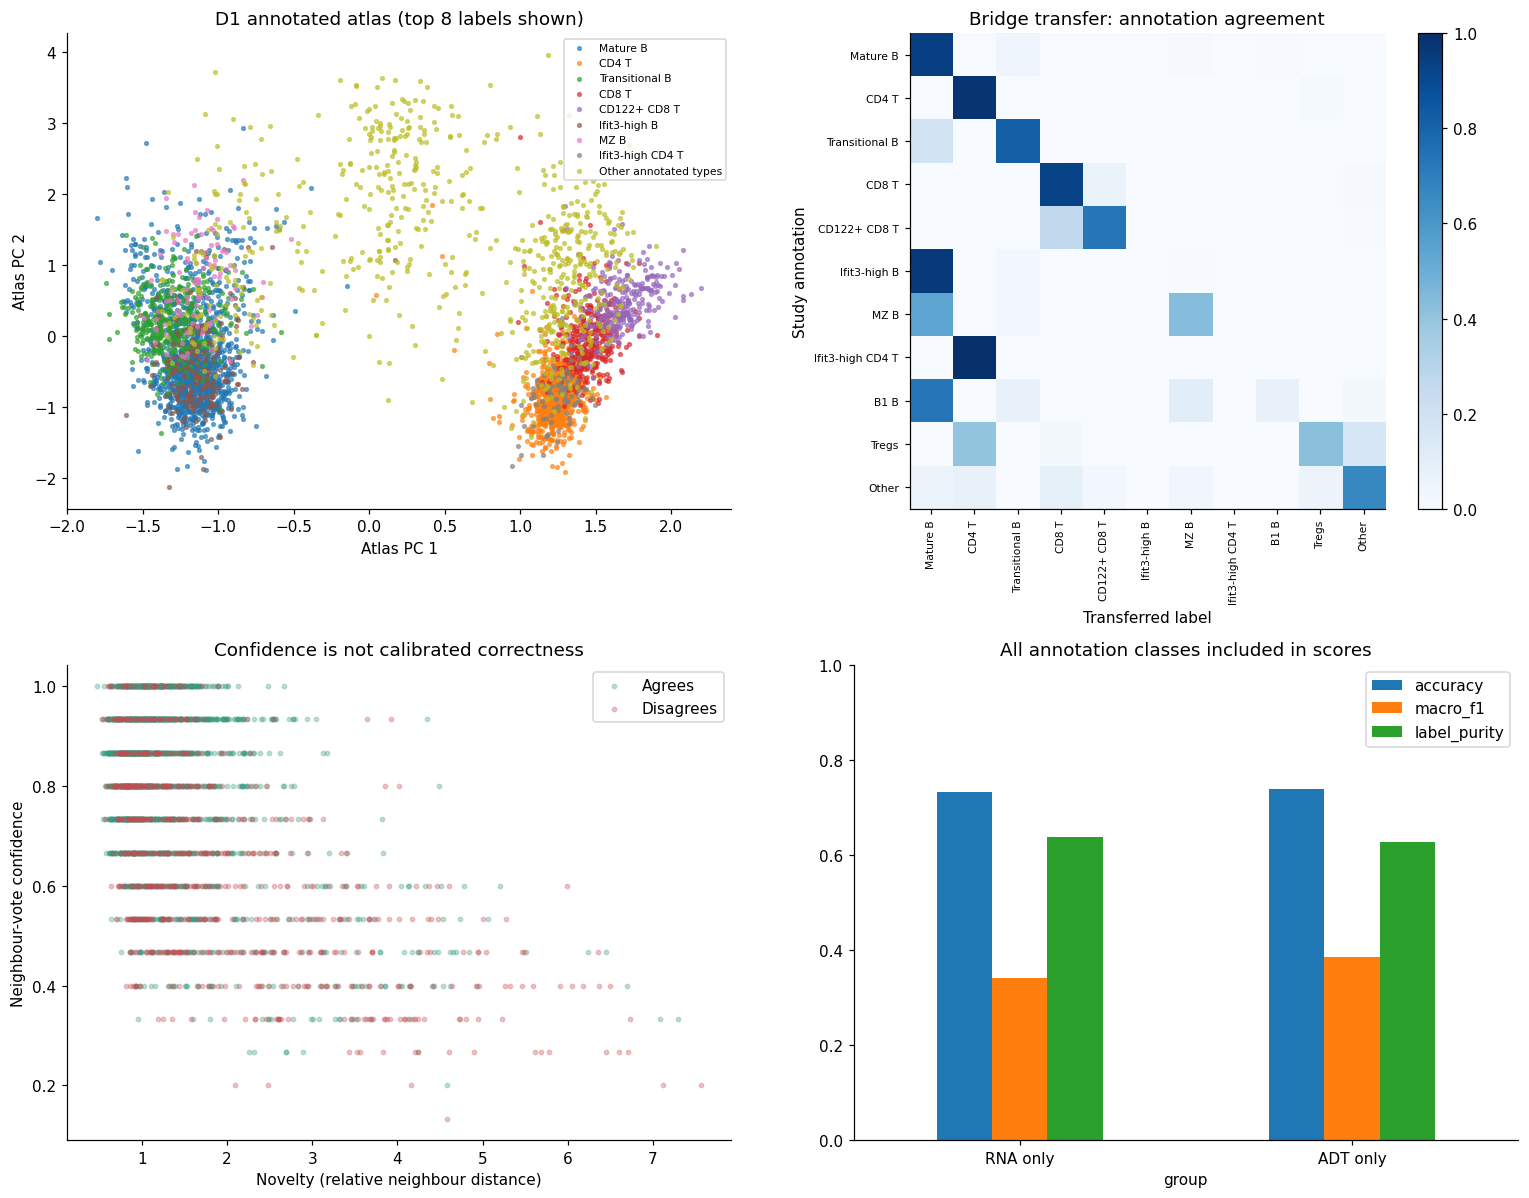

In [19]:
if RUN_ANNOTATED_ATLAS:
    bridge_labels=s_labels[sb]
    transfer_outputs={};transfer_rows=[]
    for name,ids in [('RNA only',sr),('ADT only',sa)]:
        result=transfer_labels(s_z['Paired bridge'],bridge_labels,s_z[name],k=15)
        result.index=sln.obs_names[ids];result['annotation']=s_labels[ids]
        result['correct']=result['label'].to_numpy()==s_labels[ids]
        result['bridge_supported']=np.isin(s_labels[ids],np.unique(bridge_labels))
        result.to_csv(RESULTS/('label_transfer_'+name.replace(' ','_')+'.csv'))
        transfer_outputs[name]=result
        transfer_rows.append({'group':name,'cells':len(ids),'accuracy':accuracy_score(s_labels[ids],result['label']),
            'macro_f1':f1_score(s_labels[ids],result['label'],average='macro',zero_division=0),
            'label_purity':label_purity(s_z[name],s_labels[ids]),'bridge_label_coverage':result['bridge_supported'].mean(),
            'mean_confidence':result['confidence'].mean(),'median_novelty':result['novelty'].median()})
    transfer_scores=pd.DataFrame(transfer_rows).set_index('group');display(transfer_scores)
    transfer_scores.to_csv(RESULTS/'label_transfer_summary.csv')
    all_transfers=pd.concat(transfer_outputs,names=['group','cell'])
    fig,axs=plt.subplots(2,2,figsize=(14,11))
    top=pd.Series(s_labels[s_order]).value_counts().head(8).index.tolist()
    display_labels=np.where(np.isin(s_labels[s_order],top),s_labels[s_order],'Other annotated types')
    for j,label in enumerate(top+['Other annotated types']):
        take=display_labels==label;axs[0,0].scatter(s_xy[take,0],s_xy[take,1],s=6,alpha=.6,label=label,color=plt.get_cmap('tab10')(j))
    axs[0,0].legend(fontsize=7);axs[0,0].set(title='D1 annotated atlas (top 8 labels shown)',xlabel='Atlas PC 1',ylabel='Atlas PC 2')
    truth=all_transfers['annotation'].to_numpy();pred=all_transfers['label'].to_numpy()
    top10=pd.Series(truth).value_counts().head(10).index.tolist();names=top10+['Other']
    cm=confusion_matrix(np.where(np.isin(truth,top10),truth,'Other'),np.where(np.isin(pred,top10),pred,'Other'),labels=names,normalize='true')
    im=axs[0,1].imshow(cm,vmin=0,vmax=1,cmap='Blues')
    axs[0,1].set(xticks=range(len(names)),xticklabels=names,yticks=range(len(names)),yticklabels=names,title='Bridge transfer: annotation agreement',xlabel='Transferred label',ylabel='Study annotation')
    axs[0,1].tick_params(axis='x',rotation=90,labelsize=7);axs[0,1].tick_params(axis='y',labelsize=7);fig.colorbar(im,ax=axs[0,1])
    for correct,color in [(True,'#389a80'),(False,'#c44e52')]:
        take=all_transfers['correct']==correct;axs[1,0].scatter(all_transfers.loc[take,'novelty'],all_transfers.loc[take,'confidence'],s=8,alpha=.3,c=color,label='Agrees' if correct else 'Disagrees')
    axs[1,0].set(xlabel='Novelty (relative neighbour distance)',ylabel='Neighbour-vote confidence',title='Confidence is not calibrated correctness');axs[1,0].legend()
    transfer_scores[['accuracy','macro_f1','label_purity']].plot.bar(ax=axs[1,1],ylim=(0,1),rot=0)
    axs[1,1].set_title('All annotation classes included in scores')
    fig.tight_layout();fig.savefig(RESULTS/'annotated_label_transfer.png',dpi=160);plt.show()


### Reading transfer confidence and novelty
Confidence is the fraction of neighbours voting for the selected label, not a calibrated probability of being correct. Novelty is mean query-to-reference neighbour distance divided by a typical reference-to-reference distance. A confident prediction can still be far from reference support. Accuracy and macro-F1 include labels absent from the bridge; `bridge_label_coverage` reports that limitation explicitly. The plotted confusion matrix groups rare types for readability; CSV metrics retain all types.

## 5. Add a real new batch while freezing the atlas
D2 cells did not participate in feature fitting or atlas training. Half of the sampled D2 cells fit the new cohort's input shift and decoder-conditioning row; the other half are evaluated before and after adaptation. No D2 labels enter either optimization. This is within-study batch transfer, not evidence of transfer to an unrelated study or unseen donors.

The comparison includes mixing, annotation agreement, label purity, confidence and novelty, and verifies that the D1 embeddings stay unchanged. We use the **same D1-fitted 2D projection before and after**. We also inspect learned RNA-PC shifts. There is no known true technical shift in these real data, so we cannot honestly report a cosine similarity to a true correction. Larger mixing alone is not necessarily better: composition and biological differences can also be removed.

**Included-run interpretation:** RNA-only and ADT-only annotation agreement were 69.9% and 68.7%, respectively, while macro-F1 was 0.36 and 0.30. The lower macro-F1 exposes uneven performance across annotation classes. High average accuracy should not be read as reliable identification of every rare state.


,group,exactly_equal,max_abs_change
0,RNA only,True,0.0
1,ADT only,True,0.0
2,Paired bridge,True,0.0


Original state tensors changed: []


,accuracy,macro_f1,query_label_purity,balanced_batch_mixing,mean_confidence,median_novelty,bridge_label_coverage
setting,,,,,,,
Before,0.6425,0.283086,0.558833,0.252000,0.743417,2.234479,0.995
After,0.6750,0.314633,0.560250,0.490083,0.753083,1.598416,0.995


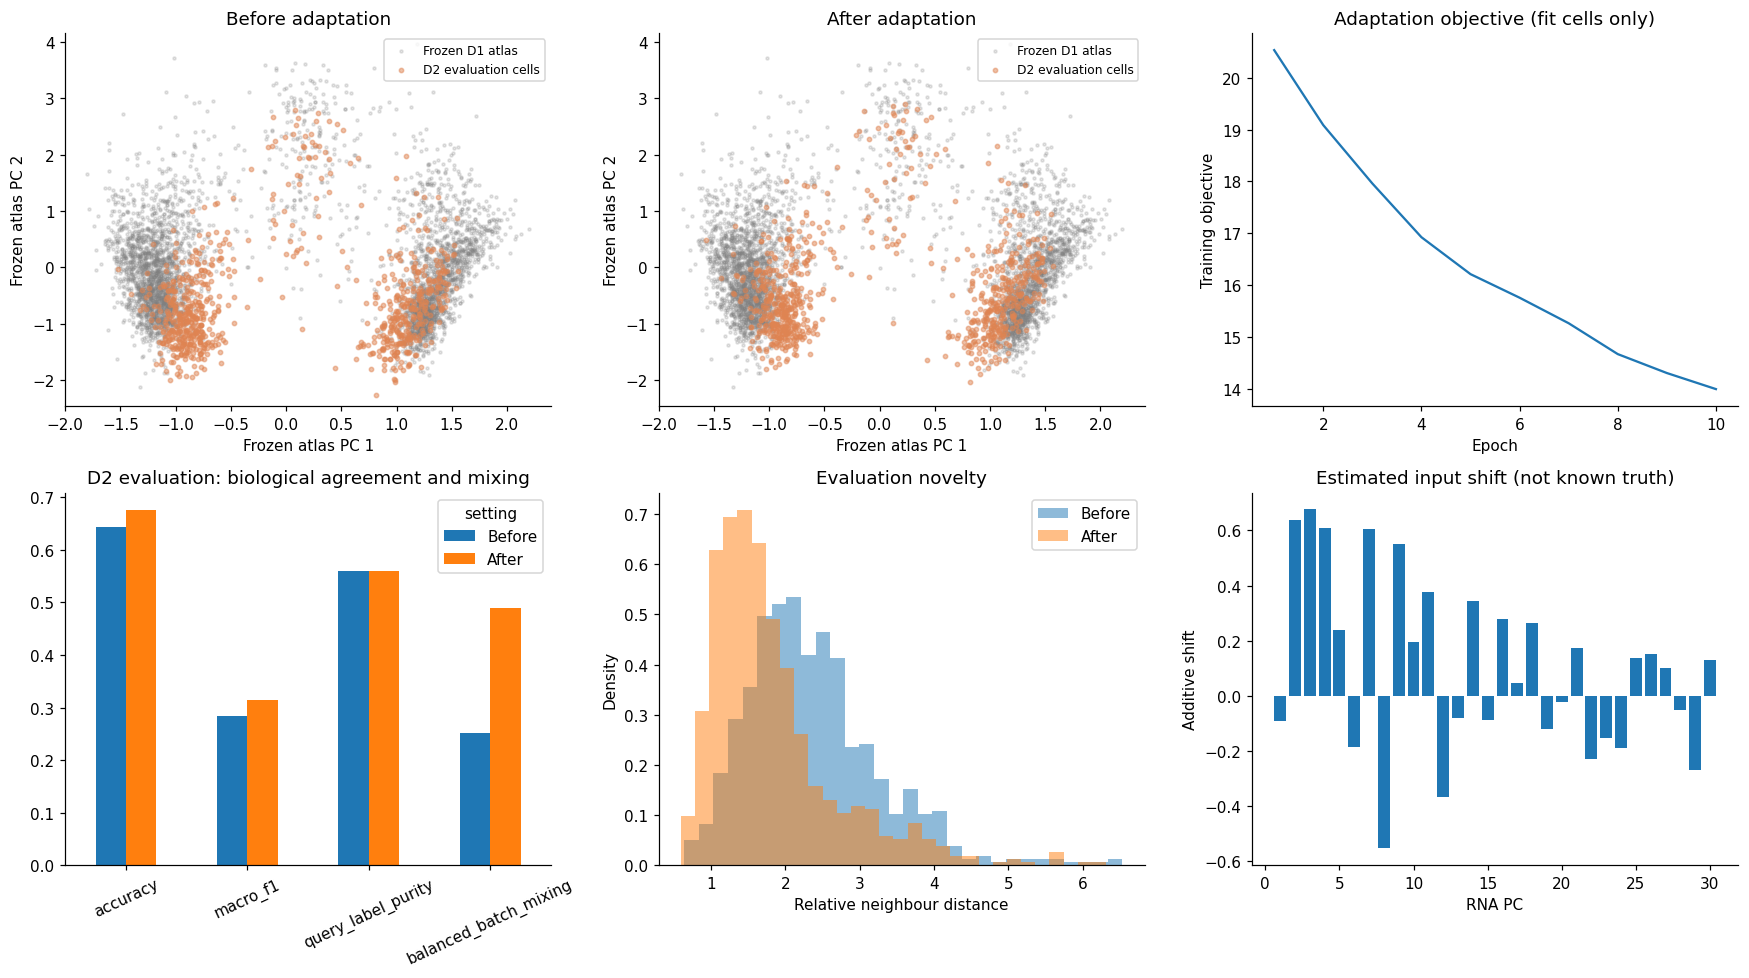

In [20]:
if RUN_ANNOTATED_ATLAS:
    s_atlas.eval()
    old_z={k:v.copy() for k,v in s_z.items()}
    old_params={k:v.detach().cpu().clone() for k,v in s_atlas.state_dict().items()}
    baseline_code=s_loader.cohort_codes['RNA only']
    new_fit={'rna':s_r[adapt_idx].copy()};new_eval={'rna':s_r[eval_idx].copy()}
    before=encode_cohort(s_atlas,new_eval,cohort=baseline_code)
    adaptation=adapt_to_cohort(s_atlas,make_loader(new_fit,batch_size=128,shuffle=True),
        reference_z=s_joined,n_epochs=ADAPT_EPOCHS,lr=.01,seed=SEED)
    after=encode_cohort(s_atlas,new_eval,cohort=adaptation['code'])
    unchanged=[]
    for k,data in s_cohorts.items():
        now=encode_cohort(s_atlas,data,cohort=s_loader.cohort_codes[k])
        unchanged.append({'group':k,'exactly_equal':np.array_equal(now,old_z[k]),'max_abs_change':float(np.abs(now-old_z[k]).max())})
    invariant=pd.DataFrame(unchanged);display(invariant);invariant.to_csv(RESULTS/'atlas_invariance.csv',index=False)
    if not invariant['exactly_equal'].all(): raise AssertionError('Adaptation changed original atlas embeddings.')
    # Inspect original tensor contents as well, including old rows in expanded cohort tables.
    state_now=s_atlas.state_dict();changed=[]
    for k,v in old_params.items():
        current=state_now[k].detach().cpu()
        original_slice=current[tuple(slice(0,d) for d in v.shape)] if current.shape!=v.shape else current
        if not torch.equal(v,original_slice):changed.append(k)
    print('Original state tensors changed:',changed)
    if changed: raise AssertionError('Original atlas tensor contents changed.')
    ref_pick=np.random.default_rng(SEED).choice(len(s_joined),min(len(s_joined),len(eval_idx)),replace=False)
    new_scores=[];new_predictions={}
    for name,zz in [('Before',before),('After',after)]:
        prediction=transfer_labels(s_z['Paired bridge'],bridge_labels,zz,k=15)
        prediction.index=sln.obs_names[eval_idx];prediction['annotation']=s_labels[eval_idx]
        prediction.to_csv(RESULTS/('new_batch_predictions_'+name.lower()+'.csv'))
        new_predictions[name]=prediction
        merged=np.vstack([s_joined[ref_pick],zz]);batches=np.r_[np.repeat('D1',len(ref_pick)),np.repeat('D2_eval',len(zz))]
        new_scores.append({'setting':name,'accuracy':accuracy_score(s_labels[eval_idx],prediction['label']),
            'macro_f1':f1_score(s_labels[eval_idx],prediction['label'],average='macro',zero_division=0),
            'query_label_purity':label_purity(zz,s_labels[eval_idx]),'balanced_batch_mixing':cohort_mixing(merged,batches),
            'mean_confidence':prediction['confidence'].mean(),'median_novelty':prediction['novelty'].median(),
            'bridge_label_coverage':np.isin(s_labels[eval_idx],np.unique(bridge_labels)).mean()})
    adaptation_scores=pd.DataFrame(new_scores).set_index('setting');display(adaptation_scores)
    adaptation_scores.to_csv(RESULTS/'adaptation_summary.csv')
    learned_shift=s_atlas.input_shifts['rna'].weight[adaptation['code']].detach().cpu().numpy()
    pd.Series(learned_shift,index=['RNA_PC_'+str(k+1) for k in range(len(learned_shift))],name='learned_shift').to_csv(RESULTS/'learned_input_shift.csv')
    np.savez_compressed(RESULTS/'new_batch_latents.npz',before=before,after=after,cell_ids=sln.obs_names[eval_idx].to_numpy(dtype=str))
    fig,axs=plt.subplots(2,3,figsize=(16,9))
    before2=s_view.transform(before);after2=s_view.transform(after)
    limits=np.vstack([s_xy,before2,after2]);lo=limits.min(0)-.2;hi=limits.max(0)+.2
    for ax,title,xy in [(axs[0,0],'Before adaptation',before2),(axs[0,1],'After adaptation',after2)]:
        ax.scatter(s_xy[:,0],s_xy[:,1],s=4,c='gray',alpha=.2,label='Frozen D1 atlas')
        ax.scatter(xy[:,0],xy[:,1],s=8,c='#df8452',alpha=.5,label='D2 evaluation cells')
        ax.set(title=title,xlabel='Frozen atlas PC 1',ylabel='Frozen atlas PC 2',xlim=(lo[0],hi[0]),ylim=(lo[1],hi[1]));ax.legend(fontsize=8)
    axs[0,2].plot(np.arange(1,len(adaptation['history'])+1),adaptation['history']);axs[0,2].set(title='Adaptation objective (fit cells only)',xlabel='Epoch',ylabel='Training objective')
    adaptation_scores[['accuracy','macro_f1','query_label_purity','balanced_batch_mixing']].T.plot.bar(ax=axs[1,0],rot=25)
    axs[1,0].set_title('D2 evaluation: biological agreement and mixing')
    for name in ['Before','After']:
        axs[1,1].hist(new_predictions[name]['novelty'],bins=30,alpha=.5,label=name,density=True)
    axs[1,1].set(title='Evaluation novelty',xlabel='Relative neighbour distance',ylabel='Density');axs[1,1].legend()
    axs[1,2].bar(np.arange(1,len(learned_shift)+1),learned_shift)
    axs[1,2].set(title='Estimated input shift (not known truth)',xlabel='RNA PC',ylabel='Additive shift')
    fig.tight_layout();fig.savefig(RESULTS/'new_batch_adaptation.png',dpi=160);plt.show()


### Training diagnostics
These curves show the objectives optimized by each model. They have different scales and terms, so compare progress within a curve rather than declaring the lowest-valued model best. A short tutorial run may not have converged.

**Included adaptation result:** evaluation accuracy changed from 62.6% to 63.0%, macro-F1 from 0.24 to 0.28, and median novelty from 1.98 to 1.80. These descriptive changes are not a significance test. All three original atlas groups had exactly unchanged embeddings (maximum absolute change 0), and original model-state tensor contents were unchanged.


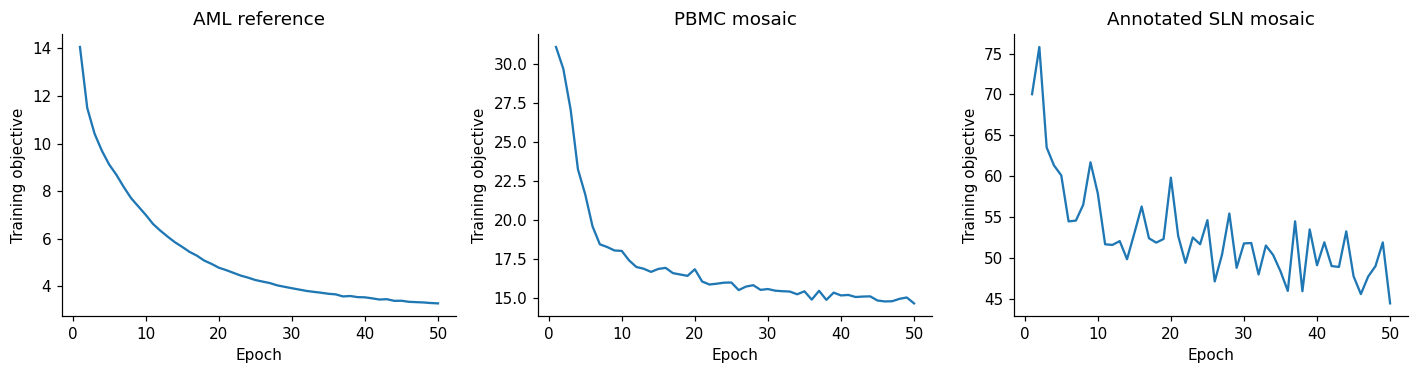

In [21]:
fig,axs=plt.subplots(1,3,figsize=(13,3.5))
for ax,title,h in [(axs[0],'AML reference',history),(axs[1],'PBMC mosaic',atlas_history if RUN_MOSAIC else None),(axs[2],'Annotated SLN mosaic',s_history if RUN_ANNOTATED_ATLAS else None)]:
    if h is not None:
        ax.plot(np.arange(1,len(h['train_loss'])+1),h['train_loss'])
        pd.DataFrame({k:v for k,v in h.items() if len(v)==len(h['train_loss'])}).to_csv(RESULTS/(title.replace(' ','_')+'_training.csv'),index=False)
    ax.set(title=title,xlabel='Epoch',ylabel='Training objective')
fig.tight_layout();fig.savefig(RESULTS/'training_diagnostics.png',dpi=160);plt.show()


## 6. Stain normalization on real H&E images

These are the TIAToolbox project's **public demonstration/test images**: its stain-normalization source, its reference image, and a TCGA-labelled H&E region (`TCGA-HE-7130-01Z-00-DX1`). The reference and TCGA example are 1,000 × 1,000 pixels; the source example is 256 × 256. These preserve tissue pixels rather than reducing them to tiny classification thumbnails. This is a suitable small example set for illustrating Macenko, **not a multi-site validation dataset**.

Use the reference image only to choose a target stain appearance. Estimate each source image's stains separately; do not pool unrelated slides. We show the tissue mask, original image, and normalized result at native pixel resolution. Color changes do not establish improved diagnosis or morphology preservation. These H&E images are unrelated to the RNA datasets and are unsuitable as a direct training set for unstained live-cell bright-field AML annotation.

Files are fetched from pinned upstream revisions and checked against SHA-256 digests. Refer to [TIAToolbox](https://github.com/TissueImageAnalytics/tiatoolbox) and its [sample data repository](https://huggingface.co/datasets/TIACentre/TIAToolBox_Remote_Samples) for attribution and source terms; downloading data does not change its license.

In the binary QC panels, **white indicates tissue** and black indicates excluded bright background. This simple optical-density mask is not a cell or nucleus segmentation.


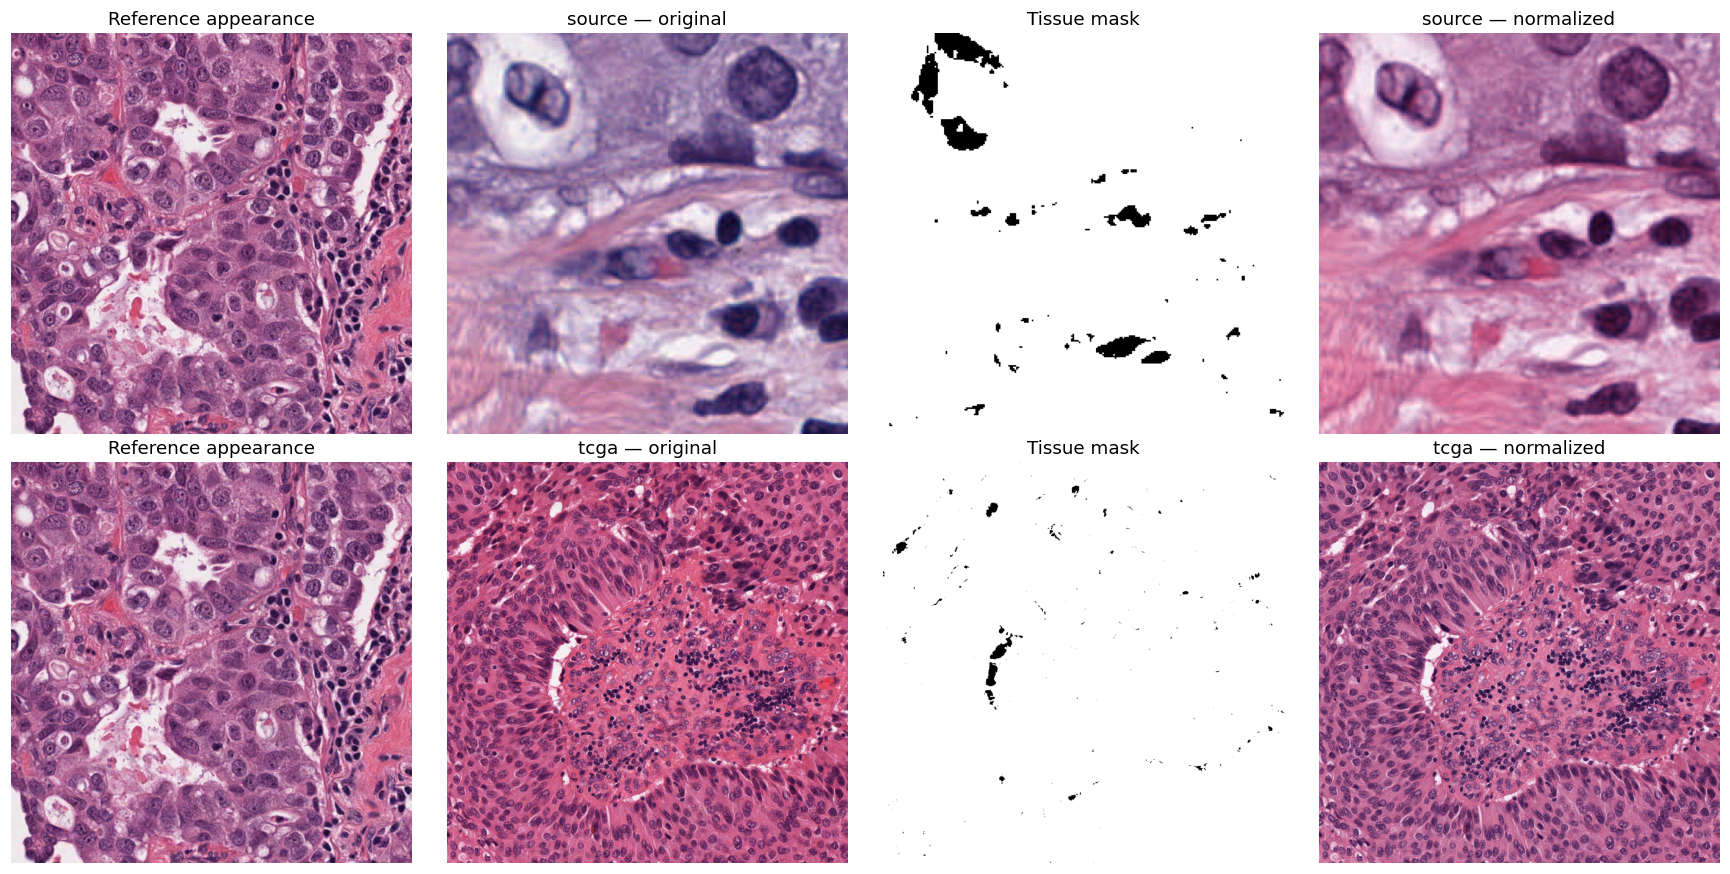

,image,height,width,tissue_fraction,mean_absolute_RGB_change
0,source,256,256,0.964020,0.048806
1,tcga,1000,1000,0.992534,0.036014


In [22]:
IMAGE_SOURCES = {'target': {'url': 'https://raw.githubusercontent.com/TissueImageAnalytics/tiatoolbox/58c0472d1c0fb4a7c40911046793a06ba9260e4d/tiatoolbox/data/target_image.png', 'sha256': '23c1e65fb65f2c5ba6aba2ad958181860e196b280a025f35e91296ba8ba51b6c'}, 'source': {'url': 'https://huggingface.co/datasets/TIACentre/TIAToolBox_Remote_Samples/resolve/c368668d6a54ec6a3ea1f9f0f15d1d2823801bd7/testdata/common/source_image.png', 'sha256': 'b3232998ab7ea8510a8e66ceb49b5d66a754fadb745fdeb03b9ddea94e79e5ca'}, 'tcga': {'url': 'https://huggingface.co/datasets/TIACentre/TIAToolBox_Remote_Samples/resolve/c368668d6a54ec6a3ea1f9f0f15d1d2823801bd7/testdata/patchextraction/TCGA-HE-7130-01Z-00-DX1.png', 'sha256': '96948511b58463766f12dc262c0345a048c043694954b0b18c28181c1f42d9de'}}

if RUN_HISTOLOGY:
    from PIL import Image
    from univii.histology import MacenkoNormalizer
    images={}
    for name,spec in IMAGE_SOURCES.items():
        p,digest=fetch_file(spec['url'],CACHE/'histology'/(name+'.png'),spec['sha256'])
        images[name]=np.asarray(Image.open(p).convert('RGB'),dtype=np.float32)/255.
    normalizer=MacenkoNormalizer(seed=SEED).fit(images['target'].transpose(2,0,1))
    sources=['source','tcga'];fig,axs=plt.subplots(len(sources),4,figsize=(16,8))
    qc=[]
    for row,name in enumerate(sources):
        rgb=images[name];chw=rgb.transpose(2,0,1)
        tissue=(-np.log(np.clip(rgb,1/255,1))>.15).any(axis=2)
        normalized=normalizer.transform(chw).transpose(1,2,0)
        if not np.isfinite(normalized).all(): raise ValueError('Nonfinite normalized image')
        panels=[images['target'],rgb,tissue,normalized]
        titles=['Reference appearance',name+' — original','Tissue mask',name+' — normalized']
        for ax,panel,title in zip(axs[row],panels,titles):ax.imshow(panel,cmap='gray' if panel.ndim==2 else None);ax.set_title(title);ax.axis('off')
        qc.append({'image':name,'height':rgb.shape[0],'width':rgb.shape[1],'tissue_fraction':float(tissue.mean()),
                   'mean_absolute_RGB_change':float(np.abs(normalized-rgb)[tissue].mean())})
        Image.fromarray(np.round(normalized*255).astype('uint8')).save(RESULTS/(name+'_normalized.png'))
    fig.tight_layout();fig.savefig(RESULTS/'histology_normalization.png',dpi=180);plt.show()
    display(pd.DataFrame(qc));pd.DataFrame(qc).to_csv(RESULTS/'histology_qc.csv',index=False)
    (RESULTS/'histology_sources.json').write_text(json.dumps(IMAGE_SOURCES,indent=2))


## Reproducibility and interpretation

- Default figures are teaching-run outputs; short training is not evidence of convergence or superiority.
- AML null-donor annotation agreement is not an independent leukemia genotype endpoint. Selecting models on BM3 consumes that holdout.
- Mosaic cells are disjoint across modality groups, but originate from one assay. Compare donors and technologies before claiming cross-study transfer.
- A pleasing embedding or closer stain colors is not sufficient validation. Preserve sample-level evaluation and inspect failure cases.
- Geometry sweeps retrain all variants with matched settings. Evaluate additional held-out donors before choosing a winner.
- Commit this notebook and its small embedded figures. Keep `data/`, `results/`, downloaded inputs and model weights out of Git.

**Sources:** van Galen et al., *Cell* (2019), [GSE116256](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE116256); [10x Genomics PBMC5k source matrix](https://cf.10xgenomics.com/samples/cell-exp/3.0.2/5k_pbmc_protein_v3/5k_pbmc_protein_v3_filtered_feature_bc_matrix.h5); [TIAToolbox stain-normalization tutorial](https://tia-toolbox.readthedocs.io/en/stable/_notebooks/jnb/02-stain-normalization.html); Macenko et al., IEEE ISBI (2009), [doi:10.1109/ISBI.2009.5193250](https://doi.org/10.1109/ISBI.2009.5193250).

- The SLN labels are original study annotations, not experimental ground truth. D2 adaptation and evaluation cells are disjoint; they remain from the same recorded batch.
- New-batch adaptation can worsen annotation agreement even if mixing rises. The notebook reports both outcomes without selecting the better-looking result.


In [23]:
import importlib.metadata
versions={p:importlib.metadata.version(p) for p in ['univii','torch','numpy','pandas','anndata','scipy','scikit-learn','matplotlib','Pillow']}
manifest={'data_mode':DATA_MODE,'epochs':N_EPOCHS,'latent_dim':LATENT_DIM,'seed':SEED,'versions':versions,
          'aml_query_samples':list(PUBLIC_AML_SAMPLES),'geometry_sweep':RUN_GEOMETRY_SWEEP,
          'mosaic':RUN_MOSAIC,'histology':RUN_HISTOLOGY,'annotated_atlas':RUN_ANNOTATED_ATLAS,
          'adapt_epochs':ADAPT_EPOCHS,'reference_batch':REFERENCE_BATCH,'new_batch':NEW_BATCH,
          'max_reference_cells':MAX_REFERENCE_CELLS,'max_new_cells':MAX_NEW_CELLS}
(RESULTS/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
display(pd.Series(versions,name='Version').to_frame())
print('Results saved:',RESULTS)


,Version
univii,2.0.0
torch,2.14.1+cu132
numpy,2.2.6
pandas,2.3.3
anndata,0.11.4
scipy,1.15.3
scikit-learn,1.7.2
matplotlib,3.10.9
Pillow,12.3.0


Results saved: results\toolkit_20261111_155412_430146
